# UNISOLAR Dataset Exploration

## Project
Solar Power Forecasting using Hybrid XGBoost-LSTM

## Dataset
UNISOLAR Solar Power Generation Dataset

## Mục tiêu
Notebook này thực hiện phân tích dữ liệu khám phá (EDA) trên bộ dữ liệu UNISOLAR
nhằm phục vụ việc dự báo ngắn hạn sản lượng điện mặt trời.


## 1. Import thư viện

In [221]:
import os
import glob
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.preprocessing import StandardScaler

from xgboost import XGBRegressor

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

pd.set_option("display.max_columns", None)

## 2. Load file

In [222]:
def find_file(filename):
    files = glob.glob(
        f"/kaggle/input/**/{filename}",
        recursive=True
    )
    
    if len(files) == 0:
        raise FileNotFoundError(
            f"Không tìm thấy file: {filename}"
        )
    
    print(filename, "->", files[0])
    return files[0]


solar_path = find_file(
    "Solar_Energy_Generation.csv"
)

site_path = find_file(
    "Solar_Site_Details.csv"
)

monthly_path = find_file(
    "Monthly_Summary_Solar.csv"
)

irradiance_path = find_file(
    "Solar_Irradiance.csv"
)

Solar_Energy_Generation.csv -> /kaggle/input/datasets/cdaclab/unisolar/unisolar/Solar_Energy_Generation.csv
Solar_Site_Details.csv -> /kaggle/input/datasets/cdaclab/unisolar/unisolar/Solar_Site_Details.csv
Monthly_Summary_Solar.csv -> /kaggle/input/datasets/cdaclab/unisolar/unisolar/Monthly_Summary_Solar.csv
Solar_Irradiance.csv -> /kaggle/input/datasets/maiemm/solar-irradiance/Solar_Irradiance.csv


In [223]:
weather_files = glob.glob(
    "/kaggle/input/**/Weather_Data_*all.csv",
    recursive=True
)

print(weather_files)

weather_path = weather_files[0]

['/kaggle/input/datasets/cdaclab/unisolar/unisolar/Weather_Data_reordered_all.csv']


## 3. Đọc dữ liệu

In [224]:
solar = pd.read_csv(solar_path)

weather = pd.read_csv(weather_path)

site = pd.read_csv(site_path)

monthly = pd.read_csv(monthly_path)

irradiance = pd.read_csv(irradiance_path)

In [225]:
print("Solar:", solar.shape)
print("Weather:", weather.shape)
print("Site:", site.shape)
print("Monthly:", monthly.shape)
print("Irradiance:", irradiance.shape)

Solar: (2731946, 4)
Weather: (371769, 8)
Site: (42, 10)
Monthly: (1176, 7)
Irradiance: (102360, 4)


## 4. Xem cấu trúc dữ liệu

In [226]:
datasets = {
    "Solar": solar,
    "Weather": weather,
    "Site": site,
    "Monthly": monthly,
    "Irradiance": irradiance
}

for name, df in datasets.items():
    print("\n========================")
    print(name)
    print("========================")
    
    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())
    
    display(df.head())


Solar
Shape: (2731946, 4)
Columns:
['CampusKey', 'SiteKey', 'Timestamp', 'SolarGeneration']


,CampusKey,SiteKey,Timestamp,SolarGeneration
0,2,1,2020-01-01 00:15:00,NaN
1,2,1,2020-01-01 00:30:00,NaN
2,2,1,2020-01-01 00:45:00,NaN
3,2,1,2020-01-01 01:00:00,NaN
4,2,1,2020-01-01 01:15:00,NaN



Weather
Shape: (371769, 8)
Columns:
['CampusKey', 'Timestamp', 'ApparentTemperature', 'AirTemperature', 'DewPointTemperature', 'RelativeHumidity', 'WindSpeed', 'WindDirection']


,CampusKey,Timestamp,ApparentTemperature,AirTemperature,DewPointTemperature,RelativeHumidity,WindSpeed,WindDirection
0,1,2020-01-01 00:00:00,13.666667,13.880000,8.960000,72.400000,0.000000,188.133333
1,1,2020-01-01 00:15:00,13.206667,13.666667,9.040000,73.466667,1.200000,203.866667
2,1,2020-01-01 00:30:00,12.840000,13.553333,9.053333,74.000000,2.520000,222.800000
3,1,2020-01-01 00:45:00,12.113333,13.506667,9.100000,74.466667,5.986667,231.133333
4,1,2020-01-01 01:00:00,11.946667,13.260000,9.266667,76.533333,5.946667,247.866667



Site
Shape: (42, 10)
Columns:
['CampusKey', 'SiteKey', 'kWp', 'Number of panels', 'Panel', 'Inverter', 'Optimizers', 'Metric', 'lat', 'Lon']


,CampusKey,SiteKey,kWp,Number of panels,Panel,Inverter,Optimizers,Metric,lat,Lon
0,2,1,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
1,2,2,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
2,2,3,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
3,2,4,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
4,2,5,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679



Monthly
Shape: (1176, 7)
Columns:
['SiteKey', 'Year', 'Month', 'DataStatus', 'AverageSolarGeneration', 'MaxSolarGeneration', 'MinSolarGeneration']


,SiteKey,Year,Month,DataStatus,AverageSolarGeneration,MaxSolarGeneration,MinSolarGeneration
0,1,2020,January,True,10.157125,21.778,0.101
1,2,2020,January,True,8.536875,18.553,0.100
2,3,2020,January,True,6.309834,13.322,0.103
3,4,2020,January,False,NaN,NaN,NaN
4,5,2020,January,False,NaN,NaN,NaN



Irradiance
Shape: (102360, 4)
Columns:
['CloudOpacity', 'Ghi', 'Timestamp_UTC', 'Campus']


,CloudOpacity,Ghi,Timestamp_UTC,Campus
0,15.5,823,2019-12-31 00:00:00,Bundoora
1,0.0,1063,2019-12-31 01:00:00,Bundoora
2,0.0,1090,2019-12-31 02:00:00,Bundoora
3,0.0,1049,2019-12-31 03:00:00,Bundoora
4,0.0,948,2019-12-31 04:00:00,Bundoora


## 5. Chuyển timestamp

In [227]:
#solar and weather
solar["Timestamp"] = pd.to_datetime(
    solar["Timestamp"],
    errors="coerce"
)

weather["Timestamp"] = pd.to_datetime(
    weather["Timestamp"],
    errors="coerce"
)

In [228]:
#irradiance
irradiance["Timestamp_UTC"] = pd.to_datetime(
    irradiance["Timestamp_UTC"],
    errors="coerce",
    utc=True
)
irradiance["Timestamp"] = (
    irradiance["Timestamp_UTC"]
    .dt.tz_convert("Australia/Melbourne")
    .dt.tz_localize(None)
)
irradiance[
    ["Timestamp_UTC", "Timestamp", "Ghi"]
].head()

,Timestamp_UTC,Timestamp,Ghi
0,2019-12-31 00:00:00+00:00,2019-12-31 11:00:00,823
1,2019-12-31 01:00:00+00:00,2019-12-31 12:00:00,1063
2,2019-12-31 02:00:00+00:00,2019-12-31 13:00:00,1090
3,2019-12-31 03:00:00+00:00,2019-12-31 14:00:00,1049
4,2019-12-31 04:00:00+00:00,2019-12-31 15:00:00,948


In [229]:
print("Solar dtype:")
print(solar["Timestamp"].dtype)

print("\nWeather dtype:")
print(weather["Timestamp"].dtype)

print("\nIrradiance dtype:")
print(irradiance["Timestamp_UTC"].dtype)

Solar dtype:
datetime64[ns]

Weather dtype:
datetime64[ns]

Irradiance dtype:
datetime64[ns, UTC]


In [230]:
print("NaT Solar:",
      solar["Timestamp"].isna().sum())

print("NaT Weather:",
      weather["Timestamp"].isna().sum())

print("NaT Irradiance:",
      irradiance["Timestamp_UTC"].isna().sum())

NaT Solar: 0
NaT Weather: 0
NaT Irradiance: 0


## 6. Kiểm tra missing

In [231]:
def missing_summary(df):
    
    result = pd.DataFrame({
        "Missing": df.isna().sum(),
        "Missing_Percent":
            df.isna().mean() * 100
    })
    
    return result.sort_values(
        "Missing_Percent",
        ascending=False
    )


display(missing_summary(solar))
display(missing_summary(weather))
display(missing_summary(irradiance))
display(missing_summary(site))
display(missing_summary(monthly))

,Missing,Missing_Percent
SolarGeneration,1536301,56.234677
CampusKey,0,0.000000
SiteKey,0,0.000000
Timestamp,0,0.000000


,Missing,Missing_Percent
WindSpeed,162890,43.814842
WindDirection,162890,43.814842
AirTemperature,107113,28.811708
ApparentTemperature,107113,28.811708
RelativeHumidity,107113,28.811708
DewPointTemperature,107113,28.811708
CampusKey,0,0.000000
Timestamp,0,0.000000


,Missing,Missing_Percent
CloudOpacity,0,0.0
Ghi,0,0.0
Timestamp_UTC,0,0.0
Campus,0,0.0
Timestamp,0,0.0


,Missing,Missing_Percent
Optimizers,19,45.238095
kWp,17,40.476190
Inverter,17,40.476190
Metric,17,40.476190
Panel,17,40.476190
Number of panels,17,40.476190
SiteKey,0,0.000000
CampusKey,0,0.000000
lat,0,0.000000
Lon,0,0.000000


,Missing,Missing_Percent
MinSolarGeneration,200,17.006803
MaxSolarGeneration,200,17.006803
AverageSolarGeneration,200,17.006803
Month,0,0.000000
Year,0,0.000000
SiteKey,0,0.000000
DataStatus,0,0.000000


## 7. kiểm tra duplicate

In [232]:
# 1. Solar Generation
print("Solar duplicate:")
print(
    solar.duplicated(
        subset=["CampusKey", "SiteKey", "Timestamp"]
    ).sum()
)

# 2. Weather
print("Weather duplicate:")
print(
    weather.duplicated(
        subset=["CampusKey", "Timestamp"]
    ).sum()
)

# 3. Solar Site Details
print("Site duplicate:")
print(
    site.duplicated(
        subset=["CampusKey", "SiteKey"]
    ).sum()
)

# 4. Monthly Summary
print("Monthly duplicate:")
print(
    monthly.duplicated(
        subset=["SiteKey", "Year", "Month"]
    ).sum()
)

# 5. Solar Irradiance
print("Irradiance duplicate:")
print(
    irradiance.duplicated(
        subset=["Campus", "Timestamp_UTC"]
    ).sum()
)

Solar duplicate:
0
Weather duplicate:
0
Site duplicate:
0
Monthly duplicate:
0
Irradiance duplicate:
0


## 8. Chuẩn hóa SiteKey/CampusKey

In [233]:
solar["CampusKey"] = (
    solar["CampusKey"]
    .astype("int16")
)

solar["SiteKey"] = (
    solar["SiteKey"]
    .astype("int16")
)

weather["CampusKey"] = (
    weather["CampusKey"]
    .astype("int16")
)

site["CampusKey"] = (
    site["CampusKey"]
    .astype("int16")
)

site["SiteKey"] = (
    site["SiteKey"]
    .astype("int16")
)

monthly["SiteKey"] = (
    monthly["SiteKey"]
    .astype("int16")
)

In [234]:
# Tạo một ID duy nhất cho từng hệ PV:
solar["SiteID"] = (
    solar["CampusKey"].astype(str)
    + "_"
    + solar["SiteKey"].astype(str)
)

site["SiteID"] = (
    site["CampusKey"].astype(str)
    + "_"
    + site["SiteKey"].astype(str)
)

## 9. Kiểm tra số campus và số site

In [235]:
print(
    "Số Campus trong Solar:",
    solar["CampusKey"].nunique()
)

print(
    "Số Site:",
    solar["SiteID"].nunique()
)

print(
    "\nCampusKey:"
)

print(
    sorted(
        solar["CampusKey"].unique()
    )
)

Số Campus trong Solar: 5
Số Site: 42

CampusKey:
[np.int16(1), np.int16(2), np.int16(3), np.int16(4), np.int16(5)]


## 10. Xem thông tin từng Campus

In [236]:
campus_info = (
    site
    .groupby("CampusKey")
    .agg(
        Number_of_Sites=(
            "SiteKey",
            "nunique"
        ),
        Latitude=(
            "lat",
            "median"
        ),
        Longitude=(
            "Lon",
            "median"
        )
    )
    .reset_index()
)

campus_info

,CampusKey,Number_of_Sites,Latitude,Longitude
0,1,27,-37.718287,145.050975
1,2,5,-36.111209,146.848679
2,3,8,-36.778858,144.301232
3,4,1,-34.205289,142.166556
4,5,1,-36.380319,145.406290


## 11. Xem campus trong Irradiance

In [237]:
irradiance[
    "Campus"
].value_counts()


Campus
Bundoora      20472
Bendigo       20472
Wodonga       20472
Mildura       20472
Shepparton    20472
Name: count, dtype: int64

In [238]:
print(
    irradiance["Campus"]
    .unique()
)

['Bundoora' 'Bendigo' 'Wodonga' 'Mildura' 'Shepparton']


## 12. Kiểm tra khoảng thời gian

In [239]:
#solar
solar_range = (
    solar
    .groupby("CampusKey")["Timestamp"]
    .agg(
        Start="min",
        End="max",
        Rows="count"
    )
)

solar_range

,Start,End,Rows
CampusKey,,,
1,2020-01-01 00:15:00,2022-04-23 23:45:00,1720219
2,2020-01-01 00:15:00,2022-04-23 23:45:00,332387
3,2020-01-01 00:15:00,2022-04-23 23:45:00,520702
4,2020-01-01 00:15:00,2022-04-23 23:45:00,79319
5,2020-01-01 00:15:00,2022-04-23 23:45:00,79319


In [240]:
#weather
weather_range = (
    weather
    .groupby("CampusKey")["Timestamp"]
    .agg(
        Start="min",
        End="max",
        Rows="count"
    )
)

weather_range

,Start,End,Rows
CampusKey,,,
1,2020-01-01 00:00:00,2022-04-23 22:00:00,81017
2,2020-01-01 00:00:00,2022-04-23 22:00:00,81017
3,2020-01-01 00:00:00,2022-04-23 22:00:00,81017
4,2020-01-01 00:00:00,2022-04-23 22:00:00,81017
5,2020-12-13 01:00:00,2022-04-23 22:00:00,47701


In [241]:
#irradiance
irradiance_range = (
    irradiance
    .groupby("Campus")["Timestamp_UTC"]
    .agg(
        Start="min",
        End="max",
        Rows="count"
    )
)

irradiance_range

,Start,End,Rows
Campus,,,
Bendigo,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472
Bundoora,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472
Mildura,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472
Shepparton,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472
Wodonga,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472


## 13. Tạo mapping CampusKey → Campus

In [242]:
campus_map = {
    1: "Bundoora",
    2: "Wodonga",
    3: "Bendigo",
    4: "Mildura",
    5: "Shepparton"
}

solar["Campus"] = solar["CampusKey"].map(campus_map)
weather["Campus"] = weather["CampusKey"].map(campus_map)
site["Campus"] = site["CampusKey"].map(campus_map)

## 14. Kiểm tra mapping

In [243]:
print(solar[
    ["CampusKey", "Campus"]
].drop_duplicates().sort_values("CampusKey"))

         CampusKey      Campus
853089           1    Bundoora
0                2     Wodonga
332387           3     Bendigo
2573308          4     Mildura
2652627          5  Shepparton


In [244]:
print("Solar campuses:")
print(sorted(solar["Campus"].dropna().unique()))

print("\nIrradiance campuses:")
print(sorted(irradiance["Campus"].dropna().unique()))

Solar campuses:
['Bendigo', 'Bundoora', 'Mildura', 'Shepparton', 'Wodonga']

Irradiance campuses:
['Bendigo', 'Bundoora', 'Mildura', 'Shepparton', 'Wodonga']


## 15.  Thêm metadata site vào Solar

In [245]:
site_meta = site[
    [
        "CampusKey",
        "SiteKey",
        "kWp",
        "Number of panels",
        "lat",
        "Lon"
    ]
].copy()

In [246]:
#merge
solar = solar.merge(
    site_meta,
    on=["CampusKey", "SiteKey"],
    how="left",
    validate="many_to_one"
)

In [247]:
solar.head()

,CampusKey,SiteKey,Timestamp,SolarGeneration,SiteID,Campus,kWp,Number of panels,lat,Lon
0,2,1,2020-01-01 00:15:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679
1,2,1,2020-01-01 00:30:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679
2,2,1,2020-01-01 00:45:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679
3,2,1,2020-01-01 01:00:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679
4,2,1,2020-01-01 01:15:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679


## 16. Kiểm tra merge metadata

In [248]:
print("Solar shape:", solar.shape)

print("\nMissing metadata:")
print(
    solar[
        ["kWp", "Number of panels", "lat", "Lon"]
    ].isna().sum()
)

Solar shape: (2731946, 10)

Missing metadata:
kWp                 1132078
Number of panels    1132078
lat                       0
Lon                       0
dtype: int64


## 17. kiểm tra một ngày Solar

In [249]:
campus1_sites = (
    site.loc[
        site["CampusKey"] == 1,
        "SiteKey"
    ]
    .sort_values()
    .tolist()
)

print(campus1_sites)

[14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]


In [250]:
chosen_campus = 1
chosen_site = campus1_sites[0]

print("Campus:", chosen_campus)
print("Site:", chosen_site)

Campus: 1
Site: 14


In [251]:
temp = solar[
    (solar["CampusKey"] == chosen_campus) &
    (solar["SiteKey"] == chosen_site)
].copy()

print("Số dòng:", len(temp))
print("Ngày bắt đầu:", temp["Timestamp"].min())
print("Ngày kết thúc:", temp["Timestamp"].max())

Số dòng: 63964
Ngày bắt đầu: 2020-06-14 00:15:00
Ngày kết thúc: 2022-04-23 23:45:00


In [252]:
#ngày có nhiều giá trị SolarGeneration hợp lệ nhất
daily_count = (
    temp
    .dropna(subset=["SolarGeneration"])
    .groupby(temp["Timestamp"].dt.date)
    ["SolarGeneration"]
    .count()
)

sample_date = daily_count.idxmax()

print("Ngày được chọn:", sample_date)
print("Số điểm dữ liệu hợp lệ:", daily_count.max())

Ngày được chọn: 2020-12-28
Số điểm dữ liệu hợp lệ: 58


In [253]:
sample_day = temp[
    temp["Timestamp"].dt.date == sample_date
][
    ["Timestamp", "SolarGeneration"]
]

sample_day

,Timestamp,SolarGeneration
871566,2020-12-28 00:15:00,NaN
871567,2020-12-28 00:30:00,NaN
871568,2020-12-28 00:45:00,NaN
871569,2020-12-28 01:00:00,NaN
871570,2020-12-28 01:15:00,NaN
...,...,...
871656,2020-12-28 22:45:00,NaN
871657,2020-12-28 23:00:00,NaN
871658,2020-12-28 23:15:00,NaN
871659,2020-12-28 23:30:00,NaN


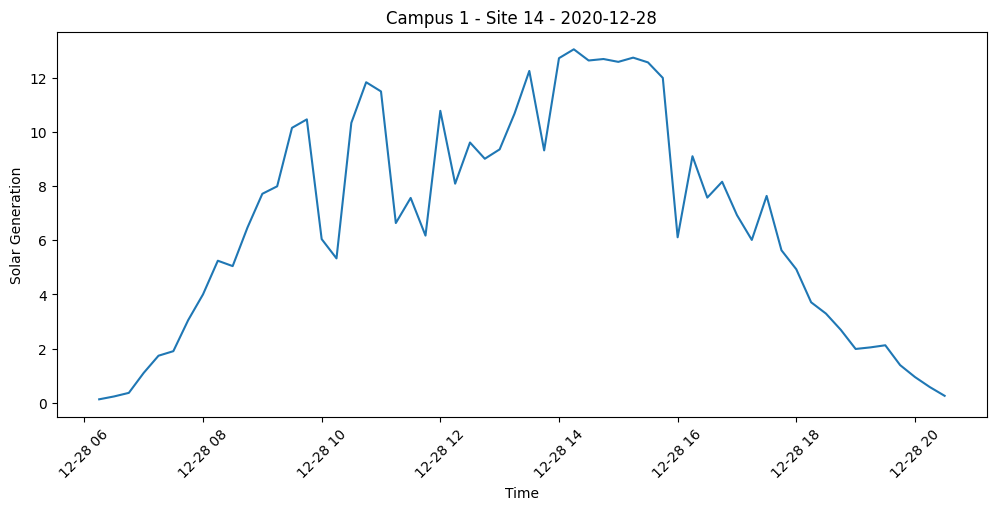

In [254]:
plt.figure(figsize=(12, 5))

plt.plot(
    sample_day["Timestamp"],
    sample_day["SolarGeneration"]
)

plt.xlabel("Time")
plt.ylabel("Solar Generation")
plt.title(
    f"Campus {chosen_campus} - Site {chosen_site} - {sample_date}"
)

plt.xticks(rotation=45)
plt.show()

##  18. thử chuyển local → UTC

In [255]:
test_time = pd.Timestamp(
    "2020-12-28 14:00:00",
    tz="Australia/Melbourne"
)

print("Local time:", test_time)
print("UTC time:", test_time.tz_convert("UTC"))

Local time: 2020-12-28 14:00:00+11:00
UTC time: 2020-12-28 03:00:00+00:00


In [256]:
#kiểm tra GHI Bundoora
check_ghi = irradiance[
    (irradiance["Campus"] == "Bundoora") &
    (irradiance["Timestamp_UTC"] >= pd.Timestamp(
        "2020-12-28 02:00:00",
        tz="UTC"
    )) &
    (irradiance["Timestamp_UTC"] <= pd.Timestamp(
        "2020-12-28 04:00:00",
        tz="UTC"
    ))
]

check_ghi[
    ["Timestamp_UTC", "Ghi", "CloudOpacity"]
]

,Timestamp_UTC,Ghi,CloudOpacity
8714,2020-12-28 02:00:00+00:00,968,10.8
8715,2020-12-28 03:00:00+00:00,848,18.6
8716,2020-12-28 04:00:00+00:00,883,6.0


## 19. Giữ lại timestamp gốc

In [257]:
solar["Timestamp_Local"] = solar["Timestamp"]
weather["Timestamp_Local"] = weather["Timestamp"]

## 20. Chuyển Solar sang UTC

In [258]:
solar["Timestamp_UTC"] = (
    solar["Timestamp_Local"]
    .dt.tz_localize(
        "Australia/Melbourne",
        ambiguous="NaT",
        nonexistent="NaT"
    )
    .dt.tz_convert("UTC")
)


## 21. Chuyển Weather sang UTC

In [259]:
weather["Timestamp_UTC"] = (
    weather["Timestamp_Local"]
    .dt.tz_localize(
        "Australia/Melbourne",
        ambiguous="NaT",
        nonexistent="NaT"
    )
    .dt.tz_convert("UTC")
)

## 22. Kiểm tra có bao nhiêu NaT do DST

In [260]:
print(
    "Solar UTC NaT:",
    solar["Timestamp_UTC"].isna().sum()
)

print(
    "Weather UTC NaT:",
    weather["Timestamp_UTC"].isna().sum()
)

Solar UTC NaT: 456
Weather UTC NaT: 92


## 23. Kiểm tra ví dụ 28/12/2020

In [261]:
check_solar = solar[
    (solar["CampusKey"] == 1) &
    (solar["SiteKey"] == 14) &
    (
        solar["Timestamp_Local"]
        == pd.Timestamp("2020-12-28 14:00:00")
    )
][
    [
        "Timestamp_Local",
        "Timestamp_UTC",
        "SolarGeneration"
    ]
]

check_solar

,Timestamp_Local,Timestamp_UTC,SolarGeneration
871621,2020-12-28 14:00:00,2020-12-28 03:00:00+00:00,12.746094


## 24. Kiểm tra Solar và Irradiance cùng timestamp

In [262]:
check_compare = check_solar.merge(
    irradiance[
        irradiance["Campus"] == "Bundoora"
    ][
        [
            "Timestamp_UTC",
            "Ghi",
            "CloudOpacity"
        ]
    ],
    on="Timestamp_UTC",
    how="left"
)

check_compare

,Timestamp_Local,Timestamp_UTC,SolarGeneration,Ghi,CloudOpacity
0,2020-12-28 14:00:00,2020-12-28 03:00:00+00:00,12.746094,848,18.6


## 25. Cài và import pvlib

In [263]:
!pip install -q pvlib

In [264]:
import pvlib

## 26. Tạo bảng tọa độ 5 campus

In [265]:
campus_coords = campus_info.copy()

campus_coords["Campus"] = (
    campus_coords["CampusKey"]
    .map(campus_map)
)

campus_coords

,CampusKey,Number_of_Sites,Latitude,Longitude,Campus
0,1,27,-37.718287,145.050975,Bundoora
1,2,5,-36.111209,146.848679,Wodonga
2,3,8,-36.778858,144.301232,Bendigo
3,4,1,-34.205289,142.166556,Mildura
4,5,1,-36.380319,145.406290,Shepparton


## 27. Hàm resample GHI

In [266]:
def resample_irradiance(
    campus_name,
    latitude,
    longitude
):
    # Lấy irradiance của 1 campus
    irr = irradiance[
        irradiance["Campus"] == campus_name
    ][
        [
            "Timestamp_UTC",
            "Ghi",
            "CloudOpacity"
        ]
    ].copy()

    irr = (
        irr
        .dropna(subset=["Timestamp_UTC"])
        .sort_values("Timestamp_UTC")
        .drop_duplicates("Timestamp_UTC")
    )

    # Tạo lưới 15 phút
    time_grid = pd.date_range(
        start=irr["Timestamp_UTC"].min(),
        end=irr["Timestamp_UTC"].max(),
        freq="15min",
        tz="UTC"
    )

    # Location dùng cho clear-sky model
    location = pvlib.location.Location(
        latitude=latitude,
        longitude=longitude,
        tz="UTC",
        name=campus_name
    )

    # Ineichen clear-sky GHI
    clearsky = location.get_clearsky(
        time_grid,
        model="ineichen"
    )

    result = pd.DataFrame({
        "Timestamp_UTC": time_grid,
        "GHI_clear": clearsky["ghi"].values
    })

    # Ghép GHI đo theo giờ vào grid 15 phút
    result = result.merge(
        irr,
        on="Timestamp_UTC",
        how="left"
    )

    # Clearness index
    result["k_t"] = np.nan

    valid = (
        (result["GHI_clear"] > 5) &
        result["Ghi"].notna()
    )

    result.loc[
        valid,
        "k_t"
    ] = (
        result.loc[valid, "Ghi"]
        /
        result.loc[valid, "GHI_clear"]
    )

    # Dùng Timestamp làm index để interpolate theo thời gian
    result = (
        result
        .set_index("Timestamp_UTC")
    )

    result["k_t_interp"] = (
        result["k_t"]
        .interpolate(
            method="time",
            limit_area="inside"
        )
    )

    # Cloud opacity cũng từ 1h -> 15min
    result["CloudOpacity_15min"] = (
        result["CloudOpacity"]
        .interpolate(
            method="time",
            limit_area="inside"
        )
    )

    # Tái tạo GHI 15 phút
    result["GHI_15min"] = (
        result["k_t_interp"]
        *
        result["GHI_clear"]
    )

    # Ban đêm clear-sky gần 0 -> GHI = 0
    result.loc[
        result["GHI_clear"] <= 5,
        "GHI_15min"
    ] = 0

    result = result.reset_index()

    result["Campus"] = campus_name

    return result

## 28. Chạy cho cả 5 campus

In [267]:
irradiance_15min_list = []

for _, row in campus_coords.iterrows():

    print("Processing:", row["Campus"])

    temp_irr = resample_irradiance(
        campus_name=row["Campus"],
        latitude=row["Latitude"],
        longitude=row["Longitude"]
    )

    irradiance_15min_list.append(
        temp_irr
    )

Processing: Bundoora
Processing: Wodonga
Processing: Bendigo
Processing: Mildura
Processing: Shepparton


In [268]:
irradiance_15min = pd.concat(
    irradiance_15min_list,
    ignore_index=True
)

print(
    "Shape:",
    irradiance_15min.shape
)

irradiance_15min.head()

Shape: (409425, 9)


,Timestamp_UTC,GHI_clear,Ghi,CloudOpacity,k_t,k_t_interp,CloudOpacity_15min,GHI_15min,Campus
0,2019-12-31 00:00:00+00:00,877.061511,823.0,15.5,0.938361,0.938361,15.500,823.000000,Bundoora
1,2019-12-31 00:15:00+00:00,909.259220,NaN,NaN,NaN,0.973261,11.625,884.946849,Bundoora
2,2019-12-31 00:30:00+00:00,938.252858,NaN,NaN,NaN,1.008162,7.750,945.910920,Bundoora
3,2019-12-31 00:45:00+00:00,963.911232,NaN,NaN,NaN,1.043063,3.875,1005.419899,Bundoora
4,2019-12-31 01:00:00+00:00,986.118777,1063.0,0.0,1.077963,1.077963,0.000,1063.000000,Bundoora


## 29. Kiểm tra tần suất

In [269]:
(
    irradiance_15min[
        irradiance_15min["Campus"] == "Bundoora"
    ]["Timestamp_UTC"]
    .diff()
    .value_counts()
    .head()
)

Timestamp_UTC
0 days 00:15:00    81884
Name: count, dtype: int64

## 30. Chuẩn bị Solar gốc

In [270]:
solar_obs = solar[
    [
        "CampusKey",
        "SiteKey",
        "Timestamp_UTC",
        "SolarGeneration"
    ]
].copy()

solar_obs = solar_obs.dropna(
    subset=["Timestamp_UTC"]
)

solar_obs["SolarGeneration"] = (
    solar_obs["SolarGeneration"]
    .astype("float32")
)

print(solar_obs.shape)
solar_obs.head()

(2731490, 4)


,CampusKey,SiteKey,Timestamp_UTC,SolarGeneration
0,2,1,2019-12-31 13:15:00+00:00,NaN
1,2,1,2019-12-31 13:30:00+00:00,NaN
2,2,1,2019-12-31 13:45:00+00:00,NaN
3,2,1,2019-12-31 14:00:00+00:00,NaN
4,2,1,2019-12-31 14:15:00+00:00,NaN


## 31. Xem khoảng thời gian của từng site 

In [271]:
site_ranges = (
    solar_obs
    .groupby(["CampusKey", "SiteKey"])["Timestamp_UTC"]
    .agg(["min", "max"])
    .reset_index()
)

site_ranges.head()

,CampusKey,SiteKey,min,max
0,1,14,2020-06-13 14:15:00+00:00,2022-04-23 13:45:00+00:00
1,1,15,2020-06-02 14:15:00+00:00,2022-04-23 13:45:00+00:00
2,1,16,2020-12-08 13:15:00+00:00,2022-04-23 13:45:00+00:00
3,1,17,2020-06-10 14:15:00+00:00,2022-04-23 13:45:00+00:00
4,1,18,2020-07-06 14:15:00+00:00,2022-04-23 13:45:00+00:00


In [272]:
print("Number of sites:", len(site_ranges))

Number of sites: 42


## 32. Tạo lưới 15 phút riêng cho từng site

In [273]:
grid_list = []

for _, row in site_ranges.iterrows():

    time_grid = pd.date_range(
        start=row["min"],
        end=row["max"],
        freq="15min",
        tz="UTC"
    )

    temp_grid = pd.DataFrame({
        "Timestamp_UTC": time_grid
    })

    temp_grid["CampusKey"] = row["CampusKey"]
    temp_grid["SiteKey"] = row["SiteKey"]

    grid_list.append(temp_grid)

In [274]:
# ghép 42 site
solar_grid = pd.concat(
    grid_list,
    ignore_index=True
)

solar_grid["CampusKey"] = (
    solar_grid["CampusKey"]
    .astype("int16")
)

solar_grid["SiteKey"] = (
    solar_grid["SiteKey"]
    .astype("int16")
)

print("Grid shape:", solar_grid.shape)
print(
    "Number of sites:",
    solar_grid[["CampusKey", "SiteKey"]]
    .drop_duplicates()
    .shape[0]
)

solar_grid.head()

Grid shape: (2784514, 3)
Number of sites: 42


,Timestamp_UTC,CampusKey,SiteKey
0,2020-06-13 14:15:00+00:00,1,14
1,2020-06-13 14:30:00+00:00,1,14
2,2020-06-13 14:45:00+00:00,1,14
3,2020-06-13 15:00:00+00:00,1,14
4,2020-06-13 15:15:00+00:00,1,14


## 33. Đưa SolarGeneration vào grid

In [275]:
panel = solar_grid.merge(
    solar_obs,
    on=[
        "CampusKey",
        "SiteKey",
        "Timestamp_UTC"
    ],
    how="left",
    validate="one_to_one"
)

print(panel.shape)

panel.head()

(2784514, 4)


,Timestamp_UTC,CampusKey,SiteKey,SolarGeneration
0,2020-06-13 14:15:00+00:00,1,14,NaN
1,2020-06-13 14:30:00+00:00,1,14,NaN
2,2020-06-13 14:45:00+00:00,1,14,NaN
3,2020-06-13 15:00:00+00:00,1,14,NaN
4,2020-06-13 15:15:00+00:00,1,14,NaN


In [276]:
print(
    "Missing SolarGeneration:",
    panel["SolarGeneration"].isna().sum()
)

print(
    "Missing percent:",
    panel["SolarGeneration"].isna().mean() * 100
)

Missing SolarGeneration: 1588869
Missing percent: 57.06090901320662


## 34. Tạo SiteID và tên Campus

In [277]:
panel["SiteID"] = (
    panel["CampusKey"].astype(str)
    + "_"
    + panel["SiteKey"].astype(str)
)

panel["Campus"] = (
    panel["CampusKey"]
    .map(campus_map)
)

In [278]:
panel[
    [
        "CampusKey",
        "SiteKey",
        "SiteID",
        "Campus"
    ]
].drop_duplicates().head(10)

,CampusKey,SiteKey,SiteID,Campus
0,1,14,1_14,Bundoora
65183,1,15,1_15,Bundoora
131422,1,16,1_16,Bundoora
179521,1,17,1_17,Bundoora
244992,1,18,1_18,Bundoora
307967,1,19,1_19,Bundoora
372094,1,20,1_20,Bundoora
437565,1,21,1_21,Bundoora
503036,1,22,1_22,Bundoora
568507,1,23,1_23,Bundoora


## 35. Ghép metadata của PV site

In [279]:
site_meta = site[
    [
        "CampusKey",
        "SiteKey",
        "kWp",
        "Number of panels",
        "lat",
        "Lon"
    ]
].copy()

In [280]:
# merge
panel = panel.merge(
    site_meta,
    on=["CampusKey", "SiteKey"],
    how="left",
    validate="many_to_one"
)

print(panel.shape)
panel.head()

(2784514, 10)


,Timestamp_UTC,CampusKey,SiteKey,SolarGeneration,SiteID,Campus,kWp,Number of panels,lat,Lon
0,2020-06-13 14:15:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975
1,2020-06-13 14:30:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975
2,2020-06-13 14:45:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975
3,2020-06-13 15:00:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975
4,2020-06-13 15:15:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975


## 36. Chuẩn bị Weather

In [281]:
weather_merge = weather[
    [
        "CampusKey",
        "Timestamp_UTC",
        "ApparentTemperature",
        "AirTemperature",
        "DewPointTemperature",
        "RelativeHumidity",
        "WindSpeed",
        "WindDirection"
    ]
].copy()

weather_merge = weather_merge.dropna(
    subset=["Timestamp_UTC"]
)

In [282]:
# Đổi float64 → float32 để đỡ RAM
weather_float_cols = [
    "ApparentTemperature",
    "AirTemperature",
    "DewPointTemperature",
    "RelativeHumidity",
    "WindSpeed",
    "WindDirection"
]

weather_merge[weather_float_cols] = (
    weather_merge[weather_float_cols]
    .astype("float32")
)

In [283]:
print(
    weather_merge.duplicated(
        subset=[
            "CampusKey",
            "Timestamp_UTC"
        ]
    ).sum()
)

0


## 37. Merge Weather vào 42 sites

In [284]:
panel = panel.merge(
    weather_merge,
    on=[
        "CampusKey",
        "Timestamp_UTC"
    ],
    how="left",
    validate="many_to_one"
)

print(panel.shape)

panel.head()

(2784514, 16)


,Timestamp_UTC,CampusKey,SiteKey,SolarGeneration,SiteID,Campus,kWp,Number of panels,lat,Lon,ApparentTemperature,AirTemperature,DewPointTemperature,RelativeHumidity,WindSpeed,WindDirection
0,2020-06-13 14:15:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,12.140000,12.853333,12.626667,98.733330,7.880000,21.133333
1,2020-06-13 14:30:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,12.740000,12.700000,12.500000,99.000000,3.720000,55.400002
2,2020-06-13 14:45:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,12.253333,12.593333,12.393333,99.000000,5.706666,63.933334
3,2020-06-13 15:00:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,11.593333,12.613334,12.413333,99.000000,9.133333,151.600006
4,2020-06-13 15:15:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,10.973333,12.820000,12.046667,95.133331,12.760000,341.266663


## 38. Chuẩn bị Irradiance 15 phút

In [285]:
irr_merge = irradiance_15min[
    [
        "Campus",
        "Timestamp_UTC",
        "GHI_clear",
        "GHI_15min",
        "k_t_interp",
        "CloudOpacity_15min"
    ]
].copy()
irr_cols = [
    "GHI_clear",
    "GHI_15min",
    "k_t_interp",
    "CloudOpacity_15min"
]

irr_merge[irr_cols] = (
    irr_merge[irr_cols]
    .astype("float32")
)

In [286]:
print(
    irr_merge.duplicated(
        subset=[
            "Campus",
            "Timestamp_UTC"
        ]
    ).sum()
)

0


## 39. Merge Irradiance

In [287]:
panel = panel.merge(
    irr_merge,
    on=[
        "Campus",
        "Timestamp_UTC"
    ],
    how="left",
    validate="many_to_one"
)

print("Final panel shape:", panel.shape)

panel.head()

Final panel shape: (2784514, 20)


,Timestamp_UTC,CampusKey,SiteKey,SolarGeneration,SiteID,Campus,kWp,Number of panels,lat,Lon,ApparentTemperature,AirTemperature,DewPointTemperature,RelativeHumidity,WindSpeed,WindDirection,GHI_clear,GHI_15min,k_t_interp,CloudOpacity_15min
0,2020-06-13 14:15:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,12.140000,12.853333,12.626667,98.733330,7.880000,21.133333,0.0,0.0,3.129371,79.074997
1,2020-06-13 14:30:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,12.740000,12.700000,12.500000,99.000000,3.720000,55.400002,0.0,0.0,3.213690,80.349998
2,2020-06-13 14:45:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,12.253333,12.593333,12.393333,99.000000,5.706666,63.933334,0.0,0.0,3.298009,81.625000
3,2020-06-13 15:00:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,11.593333,12.613334,12.413333,99.000000,9.133333,151.600006,0.0,0.0,3.382328,82.900002
4,2020-06-13 15:15:00+00:00,1,14,NaN,1_14,Bundoora,66.0,200.0,-37.718287,145.050975,10.973333,12.820000,12.046667,95.133331,12.760000,341.266663,0.0,0.0,3.466646,78.175003


## 40. Kiểm tra panel có đúng 42 site không

In [288]:
print(
    "Number of sites:",
    panel["SiteID"].nunique()
)

print(
    "Number of campuses:",
    panel["Campus"].nunique()
)

Number of sites: 42
Number of campuses: 5


## 41. Kiểm tra missing sau khi ghép

In [289]:
missing_summary(panel)

,Missing,Missing_Percent
SolarGeneration,1588869,57.060909
WindSpeed,1197100,42.991344
WindDirection,1197100,42.991344
Number of panels,1155115,41.483541
kWp,1155115,41.483541
DewPointTemperature,637432,22.892038
ApparentTemperature,637432,22.892038
RelativeHumidity,637432,22.892038
AirTemperature,637432,22.892038
SiteKey,0,0.000000


In [290]:
important_cols = [
    "SolarGeneration",
    "GHI_15min",
    "GHI_clear",
    "AirTemperature",
    "RelativeHumidity",
    "WindSpeed",
    "CloudOpacity_15min",
    "kWp"
]

missing_summary(
    panel[important_cols]
)

,Missing,Missing_Percent
SolarGeneration,1588869,57.060909
WindSpeed,1197100,42.991344
kWp,1155115,41.483541
AirTemperature,637432,22.892038
RelativeHumidity,637432,22.892038
GHI_15min,0,0.000000
GHI_clear,0,0.000000
CloudOpacity_15min,0,0.000000


## 42. Sắp xếp panel 

In [291]:
panel = (
    panel
    .sort_values(
        ["SiteID", "Timestamp_UTC"]
    )
    .reset_index(drop=True)
)

print(panel.shape)

(2784514, 20)


## 43. Tính Solar Elevation cho 42 site

In [292]:
panel["SolarElevation"] = np.nan

for site_id, idx in panel.groupby("SiteID").groups.items():

    lat = panel.loc[idx, "lat"].iloc[0]
    lon = panel.loc[idx, "Lon"].iloc[0]

    times = pd.DatetimeIndex(
        panel.loc[idx, "Timestamp_UTC"]
    )

    solar_pos = pvlib.solarposition.get_solarposition(
        time=times,
        latitude=lat,
        longitude=lon
    )

    panel.loc[idx, "SolarElevation"] = (
        solar_pos["elevation"].to_numpy()
    )

print(
    panel["SolarElevation"]
    .describe()
)

count    2.784514e+06
mean     7.934626e-01
std      3.744103e+01
min     -7.921172e+01
25%     -2.948261e+01
50%      6.590555e-01
75%      3.079987e+01
max      7.923090e+01
Name: SolarElevation, dtype: float64


In [293]:
#giảm  RAM
panel["SolarElevation"] = (
    panel["SolarElevation"]
    .astype("float32")
)

## 44. Tạo biến Night

In [294]:
GHI_THRESHOLD = 5.0

panel["Night"] = (
    (panel["SolarElevation"] <= 0) |
    (panel["GHI_15min"] < GHI_THRESHOLD)
).astype("int8")

In [295]:
panel["Night"].value_counts()

Night
1    1436702
0    1347812
Name: count, dtype: int64

In [296]:
panel["Night"].value_counts(
    normalize=True
) * 100

Night
1    51.596149
0    48.403851
Name: proportion, dtype: float64

## 45. Tách Solar missing ban đêm và ban ngày

In [297]:
night_missing = (
    panel["SolarGeneration"].isna()
    &
    (panel["Night"] == 1)
)

day_missing = (
    panel["SolarGeneration"].isna()
    &
    (panel["Night"] == 0)
)

print(
    "Total Solar missing:",
    panel["SolarGeneration"].isna().sum()
)

print(
    "Night missing:",
    night_missing.sum()
)

print(
    "Daytime missing:",
    day_missing.sum()
)

Total Solar missing: 1588869
Night missing: 1415651
Daytime missing: 173218


In [298]:
print(
    "Night missing %:",
    night_missing.mean() * 100
)

print(
    "Daytime missing %:",
    day_missing.mean() * 100
)

Night missing %: 50.84014661086279
Daytime missing %: 6.22076240234382


## 46. Điền 0 CHỈ cho missing ban đêm

In [299]:
panel.loc[
    night_missing,
    "SolarGeneration"
] = 0.0

In [300]:
print(
    "Solar missing sau khi xử lý nighttime:",
    panel["SolarGeneration"].isna().sum()
)

Solar missing sau khi xử lý nighttime: 173218


## 47. Kiểm tra giá trị Solar bất thường

In [301]:
print(
    "Negative SolarGeneration:",
    (panel["SolarGeneration"] < 0).sum()
)

print(
    panel["SolarGeneration"].describe()
)

Negative SolarGeneration: 0
count    2.611296e+06
mean     3.179691e+00
std      8.334717e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      2.792969e+00
max      9.921880e+01
Name: SolarGeneration, dtype: float64


In [302]:
print(
    "Sites có kWp:",
    site["kWp"].notna().sum()
)

print(
    "Sites thiếu kWp:",
    site["kWp"].isna().sum()
)

Sites có kWp: 25
Sites thiếu kWp: 17


In [303]:
site["Metric"].value_counts(
    dropna=False
)

Metric
kWh    25
NaN    17
Name: count, dtype: int64

## 48. Tạo lại giờ địa phương

In [304]:
panel["Timestamp_Local"] = (
    panel["Timestamp_UTC"]
    .dt.tz_convert("Australia/Melbourne")
)

panel["Hour"] = (
    panel["Timestamp_Local"].dt.hour
).astype("int8")

panel["Month"] = (
    panel["Timestamp_Local"].dt.month
).astype("int8")

panel["DayOfYear"] = (
    panel["Timestamp_Local"].dt.dayofyear
).astype("int16")

In [305]:
panel[
    [
        "Timestamp_UTC",
        "Timestamp_Local",
        "Hour",
        "Month",
        "DayOfYear"
    ]
].head()

,Timestamp_UTC,Timestamp_Local,Hour,Month,DayOfYear
0,2020-06-13 14:15:00+00:00,2020-06-14 00:15:00+10:00,0,6,166
1,2020-06-13 14:30:00+00:00,2020-06-14 00:30:00+10:00,0,6,166
2,2020-06-13 14:45:00+00:00,2020-06-14 00:45:00+10:00,0,6,166
3,2020-06-13 15:00:00+00:00,2020-06-14 01:00:00+10:00,1,6,166
4,2020-06-13 15:15:00+00:00,2020-06-14 01:15:00+10:00,1,6,166


## 49. Tạo DataStatus cơ bản

In [306]:
panel["DataStatus"] = True
#Generation âm
negative_mask = (
    panel["SolarGeneration"] < 0
)

print(
    "Negative generation:",
    negative_mask.sum()
)

panel.loc[
    negative_mask,
    "DataStatus"
] = False

Negative generation: 0


## 50. Chuẩn bị capacity cho 25 site có dữ liệu

In [307]:
capacity_info = site[
    [
        "CampusKey",
        "SiteKey",
        "kWp",
        "Metric"
    ]
].copy()

In [308]:
# chỉ những site có Metric = kWh và kWp không missing mới có bound
capacity_info["Capacity_15min"] = np.where(
    (capacity_info["Metric"] == "kWh")
    &
    (capacity_info["kWp"].notna()),
    
    capacity_info["kWp"] * 0.25,
    
    np.nan
)

In [309]:
#merge vào panel
panel = panel.merge(
    capacity_info[
        [
            "CampusKey",
            "SiteKey",
            "Capacity_15min"
        ]
    ],
    on=["CampusKey", "SiteKey"],
    how="left",
    validate="many_to_one"
)

## 51. Xem có bao nhiêu giá trị vượt capacity

In [310]:
capacity_available = (
    panel["Capacity_15min"].notna()
    &
    panel["SolarGeneration"].notna()
)

capacity_ratio = (
    panel.loc[
        capacity_available,
        "SolarGeneration"
    ]
    /
    panel.loc[
        capacity_available,
        "Capacity_15min"
    ]
)

capacity_ratio.describe(
    percentiles=[
        0.90,
        0.95,
        0.99,
        0.999
    ]
)

count    1.538410e+06
mean     1.638944e-01
std      3.666730e-01
min      0.000000e+00
50%      0.000000e+00
90%      5.209713e-01
95%      6.860808e-01
99%      1.533362e+00
99.9%    4.414336e+00
max      4.920600e+00
dtype: float64

## 52. xem site nào có capacity ratio cao

In [311]:
capacity_check = panel.loc[
    capacity_available,
    [
        "CampusKey",
        "SiteKey",
        "SiteID",
        "Timestamp_UTC",
        "SolarGeneration",
        "Capacity_15min",
        "GHI_15min"
    ]
].copy()

capacity_check["CapacityRatio"] = (
    capacity_check["SolarGeneration"]
    / capacity_check["Capacity_15min"]
)
capacity_check.sort_values(
    "CapacityRatio",
    ascending=False
).head(20)

,CampusKey,SiteKey,SiteID,Timestamp_UTC,SolarGeneration,Capacity_15min,GHI_15min,CapacityRatio
355532,1,19,1_19,2021-11-02 01:30:00+00:00,42.218750,8.58,991.302246,4.920600
323178,1,19,1_19,2020-11-30 01:00:00+00:00,42.218750,8.58,1036.000000,4.920600
358417,1,19,1_19,2021-12-02 02:45:00+00:00,42.218750,8.58,896.390869,4.920600
324042,1,19,1_19,2020-12-09 01:00:00+00:00,42.218750,8.58,1049.000000,4.920600
363020,1,19,1_19,2022-01-19 01:30:00+00:00,42.218750,8.58,1047.869019,4.920600
360915,1,19,1_19,2021-12-28 03:15:00+00:00,42.218750,8.58,994.906128,4.920600
361393,1,19,1_19,2022-01-02 02:45:00+00:00,42.218750,8.58,992.763245,4.920600
354963,1,19,1_19,2021-10-27 03:15:00+00:00,42.218750,8.58,903.047424,4.920600
365142,1,19,1_19,2022-02-10 04:00:00+00:00,42.218750,8.58,880.000000,4.920600
354386,1,19,1_19,2021-10-21 03:00:00+00:00,42.218750,8.58,866.000000,4.920600


In [312]:
capacity_by_site = (
    capacity_check
    .groupby("SiteID")
    .agg(
        Max_Ratio=("CapacityRatio", "max"),
        P99_Ratio=("CapacityRatio", lambda x: x.quantile(0.99)),
        Rows=("CapacityRatio", "size")
    )
    .sort_values("Max_Ratio", ascending=False)
)

capacity_by_site.head(15)

,Max_Ratio,P99_Ratio,Rows
SiteID,,,
1_19,4.920600,4.743954,61003
1_24,1.766642,1.689574,62406
1_33,0.859037,0.821740,62354
1_31,0.851043,0.817428,62362
1_17,0.843736,0.809213,62004
1_18,0.840924,0.809203,60167
1_25,0.835676,0.808341,60985
1_22,0.828490,0.789574,62203
1_32,0.825968,0.779935,61767


## 53. kiểm tra missing Weather còn lại

In [313]:
weather_cols = [
    "ApparentTemperature",
    "AirTemperature",
    "DewPointTemperature",
    "RelativeHumidity",
    "WindSpeed",
    "WindDirection"
]

missing_summary(
    panel[weather_cols]
)

,Missing,Missing_Percent
WindSpeed,1197100,42.991344
WindDirection,1197100,42.991344
AirTemperature,637432,22.892038
ApparentTemperature,637432,22.892038
RelativeHumidity,637432,22.892038
DewPointTemperature,637432,22.892038


## 54. interpolation Weather theo từng campus

In [314]:
weather_panel = (
    panel[
        ["CampusKey", "Timestamp_UTC"] + weather_cols
    ]
    .drop_duplicates(
        subset=["CampusKey", "Timestamp_UTC"]
    )
    .sort_values(
        ["CampusKey", "Timestamp_UTC"]
    )
    .reset_index(drop=True)
)

In [315]:
weather_panel.shape

(405135, 8)

In [316]:
# interpolation các khoảng ngắn, tối đa 4 bước = 1 giờ
for col in weather_cols:
    weather_panel[col] = (
        weather_panel
        .groupby("CampusKey")[col]
        .transform(
            lambda s: s.interpolate(
                method="linear",
                limit=4,
                limit_area="inside"
            )
        )
    )

missing_summary(
    weather_panel[weather_cols]
)

,Missing,Missing_Percent
WindSpeed,196244,48.439162
WindDirection,196244,48.439162
AirTemperature,86847,21.436558
ApparentTemperature,86847,21.436558
RelativeHumidity,86847,21.436558
DewPointTemperature,86847,21.436558


## 55. chuẩn bị IterativeImputer

In [317]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

weather_impute_cols = [
    "ApparentTemperature",
    "AirTemperature",
    "DewPointTemperature",
    "RelativeHumidity",
    "WindSpeed"
]

## 56. IterativeImputer theo từng campus

In [318]:
imputed_weather_list = []

for campus_key, group in weather_panel.groupby("CampusKey"):

    group = group.copy()

    imputer = IterativeImputer(
        max_iter=10,
        random_state=42,
        initial_strategy="median"
    )

    group[weather_impute_cols] = imputer.fit_transform(
        group[weather_impute_cols]
    )

    imputed_weather_list.append(group)

weather_panel = pd.concat(
    imputed_weather_list,
    ignore_index=True
)

In [319]:
missing_summary(
    weather_panel[weather_impute_cols]
)

,Missing,Missing_Percent
ApparentTemperature,0,0.0
AirTemperature,0,0.0
DewPointTemperature,0,0.0
RelativeHumidity,0,0.0
WindSpeed,0,0.0


## 57. WindDirection xử lý riêng

In [320]:
# với hướng gió, dùng circular representation
angle_rad = np.deg2rad(
    weather_panel["WindDirection"]
)

weather_panel["WindDir_sin"] = np.sin(angle_rad)
weather_panel["WindDir_cos"] = np.cos(angle_rad)

In [321]:
# interpolation
weather_panel["WindDir_sin"] = (
    weather_panel
    .groupby("CampusKey")["WindDir_sin"]
    .transform(
        lambda s: s.interpolate(
            limit=4,
            limit_area="inside"
        )
    )
)

weather_panel["WindDir_cos"] = (
    weather_panel
    .groupby("CampusKey")["WindDir_cos"]
    .transform(
        lambda s: s.interpolate(
            limit=4,
            limit_area="inside"
        )
    )
)
#missing dài thì fallback median
weather_panel["WindDir_sin"] = (
    weather_panel["WindDir_sin"]
    .fillna(
        weather_panel.groupby("CampusKey")["WindDir_sin"]
        .transform("median")
    )
)

weather_panel["WindDir_cos"] = (
    weather_panel["WindDir_cos"]
    .fillna(
        weather_panel.groupby("CampusKey")["WindDir_cos"]
        .transform("median")
    )
)

In [322]:
weather_panel[
    ["WindDir_sin", "WindDir_cos"]
].isna().sum()

WindDir_sin    0
WindDir_cos    0
dtype: int64

## 58. Đưa Weather đã xử lý trở lại panel

In [323]:
# xóa các cột Weather cũ đang missing
old_weather_cols = [
    "ApparentTemperature",
    "AirTemperature",
    "DewPointTemperature",
    "RelativeHumidity",
    "WindSpeed",
    "WindDirection"
]

panel = panel.drop(
    columns=old_weather_cols,
    errors="ignore"
)
# Lấy Weather sạch
weather_clean = weather_panel[
    [
        "CampusKey",
        "Timestamp_UTC",
        "ApparentTemperature",
        "AirTemperature",
        "DewPointTemperature",
        "RelativeHumidity",
        "WindSpeed",
        "WindDir_sin",
        "WindDir_cos"
    ]
].copy()
#merge
panel = panel.merge(
    weather_clean,
    on=[
        "CampusKey",
        "Timestamp_UTC"
    ],
    how="left",
    validate="many_to_one"
)

In [324]:
missing_summary(
    panel[
        [
            "ApparentTemperature",
            "AirTemperature",
            "DewPointTemperature",
            "RelativeHumidity",
            "WindSpeed",
            "WindDir_sin",
            "WindDir_cos"
        ]
    ]
)

,Missing,Missing_Percent
ApparentTemperature,0,0.0
AirTemperature,0,0.0
DewPointTemperature,0,0.0
RelativeHumidity,0,0.0
WindSpeed,0,0.0
WindDir_sin,0,0.0
WindDir_cos,0,0.0


## 59. Tạo các feature thời gian

In [325]:
# Tạo cyclical features
panel["Hour_sin"] = np.sin(
    2 * np.pi * panel["Hour"] / 24
)

panel["Hour_cos"] = np.cos(
    2 * np.pi * panel["Hour"] / 24
)

panel["Day_sin"] = np.sin(
    2 * np.pi * panel["DayOfYear"] / 365.25
)

panel["Day_cos"] = np.cos(
    2 * np.pi * panel["DayOfYear"] / 365.25
)

In [326]:
# Đổi sang float32 để tiết kiệm RAM
for col in [
    "Hour_sin",
    "Hour_cos",
    "Day_sin",
    "Day_cos"
]:
    panel[col] = panel[col].astype("float32")

In [327]:
# Kiểm tra Solar missing hiện tại
print(
    "Solar missing còn lại:",
    panel["SolarGeneration"].isna().sum()
)

print(
    "Daytime missing:",
    (
        panel["SolarGeneration"].isna()
        &
        (panel["Night"] == 0)
    ).sum()
)


Solar missing còn lại: 173218
Daytime missing: 173218


## 60. Các feature dùng để impute Solar ban ngày

In [328]:
solar_impute_cols = [
    "SolarGeneration",

    # Irradiance
    "GHI_15min",
    "GHI_clear",
    "k_t_interp",
    "CloudOpacity_15min",
    "SolarElevation",

    # Weather
    "AirTemperature",
    "ApparentTemperature",
    "DewPointTemperature",
    "RelativeHumidity",
    "WindSpeed",
    "WindDir_sin",
    "WindDir_cos",

    # Time
    "Hour_sin",
    "Hour_cos",
    "Day_sin",
    "Day_cos"
]
panel[
    solar_impute_cols[1:]
].isna().sum()

GHI_15min              0
GHI_clear              0
k_t_interp             0
CloudOpacity_15min     0
SolarElevation         0
AirTemperature         0
ApparentTemperature    0
DewPointTemperature    0
RelativeHumidity       0
WindSpeed              0
WindDir_sin            0
WindDir_cos            0
Hour_sin               0
Hour_cos               0
Day_sin                0
Day_cos                0
dtype: int64

## 61. Backup SolarGeneration trước khi impute

In [329]:
panel["SolarGeneration_before_impute"] = (
    panel["SolarGeneration"]
    .astype("float32")
)

## 62. Iterative Imputation theo từng Site

In [330]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# xử lí từng site
site_ids = panel["SiteID"].unique()

for i, site_id in enumerate(site_ids, start=1):

    print(
        f"[{i}/{len(site_ids)}] Processing {site_id}"
    )

    mask = (
        (panel["SiteID"] == site_id)
        &
        (panel["Night"] == 0)
    )

    site_day = panel.loc[
        mask,
        solar_impute_cols
    ].copy()

    missing_count = (
        site_day["SolarGeneration"]
        .isna()
        .sum()
    )

    if missing_count == 0:
        continue

    # phải có đủ dữ liệu Solar thật để học
    observed_count = (
        site_day["SolarGeneration"]
        .notna()
        .sum()
    )

    if observed_count < 50:
        continue

    imputer = IterativeImputer(
        max_iter=10,
        initial_strategy="median",
        random_state=42,
        skip_complete=True
    )

    imputed_array = (
        imputer.fit_transform(site_day)
    )

    panel.loc[
        mask,
        "SolarGeneration"
    ] = imputed_array[:, 0]

[1/42] Processing 1_14
[2/42] Processing 1_15
[3/42] Processing 1_16
[4/42] Processing 1_17
[5/42] Processing 1_18
[6/42] Processing 1_19
[7/42] Processing 1_20
[8/42] Processing 1_21
[9/42] Processing 1_22
[10/42] Processing 1_23
[11/42] Processing 1_24
[12/42] Processing 1_25
[13/42] Processing 1_26
[14/42] Processing 1_27
[15/42] Processing 1_28
[16/42] Processing 1_29
[17/42] Processing 1_30
[18/42] Processing 1_31
[19/42] Processing 1_32
[20/42] Processing 1_33
[21/42] Processing 1_34
[22/42] Processing 1_35
[23/42] Processing 1_36
[24/42] Processing 1_37
[25/42] Processing 1_38
[26/42] Processing 1_39
[27/42] Processing 1_40
[28/42] Processing 2_1
[29/42] Processing 2_2
[30/42] Processing 2_3
[31/42] Processing 2_4
[32/42] Processing 2_5
[33/42] Processing 3_10
[34/42] Processing 3_11
[35/42] Processing 3_12
[36/42] Processing 3_13
[37/42] Processing 3_6
[38/42] Processing 3_7
[39/42] Processing 3_8
[40/42] Processing 3_9
[41/42] Processing 4_41
[42/42] Processing 5_42


In [331]:
# Kiểm tra Solar missing sau IterativeImputer
print(
    "Missing Solar after iterative imputation:",
    panel["SolarGeneration"].isna().sum()
)

Missing Solar after iterative imputation: 0


## 63. Kiểm tra tính vật lý sau imputation

In [332]:
print(
    "Negative:",
    (panel["SolarGeneration"] < 0).sum()
)

print(
    panel["SolarGeneration"].describe()
)

Negative: 40200
count    2.784514e+06
mean     3.395687e+00
std      8.747110e+00
min     -2.801565e+01
25%      0.000000e+00
50%      0.000000e+00
75%      3.169706e+00
max      9.921880e+01
Name: SolarGeneration, dtype: float64


In [333]:
panel["SolarGeneration"] = (
    panel["SolarGeneration"]
    .clip(lower=0)
)

## 64. Clear-sky index

In [334]:
panel["ClearSkyIndex"] = (
    panel["GHI_15min"]
    /
    panel["GHI_clear"].replace(0, np.nan)
)

panel["ClearSkyIndex"] = (
    panel["ClearSkyIndex"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .clip(lower=0)
    .astype("float32")
)

## 65. Normalized GHI

In [335]:
panel["GHI_Normalized"] = (
    panel["GHI_15min"]
    /
    (panel["GHI_clear"] + 1e-6)
)

panel["GHI_Normalized"] = (
    panel["GHI_Normalized"]
    .clip(lower=0)
    .astype("float32")
)

## 66. Temperature difference

In [336]:
panel["TempDiff"] = (
    panel["ApparentTemperature"]
    -
    panel["AirTemperature"]
).astype("float32")

## 67. Vapor pressure

In [337]:
panel["VaporPressure"] = (
    0.6108 *
    np.exp(
        (17.27 * panel["DewPointTemperature"])
        /
        (panel["DewPointTemperature"] + 237.3)
    )
).astype("float32")

## 68. Cyclical time features

In [338]:
panel["Hour_sin"] = np.sin(
    2 * np.pi * panel["Hour"] / 24
).astype("float32")

panel["Hour_cos"] = np.cos(
    2 * np.pi * panel["Hour"] / 24
).astype("float32")

panel["Day_sin"] = np.sin(
    2 * np.pi * panel["DayOfYear"] / 365.25
).astype("float32")

panel["Day_cos"] = np.cos(
    2 * np.pi * panel["DayOfYear"] / 365.25
).astype("float32")

## 69. Kiểm tra các physics features

In [339]:
physics_cols = [
    "GHI_15min",
    "GHI_clear",
    "ClearSkyIndex",
    "GHI_Normalized",
    "SolarElevation",
    "TempDiff",
    "VaporPressure"
]

panel[physics_cols].describe()

,GHI_15min,GHI_clear,ClearSkyIndex,GHI_Normalized,SolarElevation,TempDiff,VaporPressure
count,2.784514e+06,2.784514e+06,2.784514e+06,2.784514e+06,2.784514e+06,2.784514e+06,2.784514e+06
mean,1.928356e+02,2.472660e+02,4.354455e-01,4.354455e-01,7.934627e-01,-1.951634e+00,1.221814e+00
std,2.806069e+02,3.296128e+02,7.315027e-01,7.315027e-01,3.741159e+01,1.818937e+00,3.473348e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-7.921172e+01,-1.170000e+01,2.540043e-01
25%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-2.948261e+01,-3.106739e+00,9.646451e-01
50%,0.000000e+00,9.503597e-01,0.000000e+00,0.000000e+00,6.590555e-01,-2.000000e+00,1.163665e+00
75%,3.313659e+02,4.836176e+02,7.781247e-01,7.781247e-01,3.079987e+01,-7.933331e-01,1.407195e+00
max,1.128000e+03,1.070220e+03,2.218914e+01,2.218914e+01,7.923090e+01,5.300001e+00,3.228662e+00


In [340]:
missing_summary(
    panel[physics_cols]
)

,Missing,Missing_Percent
GHI_15min,0,0.0
GHI_clear,0,0.0
ClearSkyIndex,0,0.0
GHI_Normalized,0,0.0
SolarElevation,0,0.0
TempDiff,0,0.0
VaporPressure,0,0.0


## 70. Lưu checkpoint

In [341]:
panel.to_pickle(
    "/kaggle/working/panel_preprocessed.pkl"
)

## 71. Thêm Solar Zenith

In [342]:
panel["SolarZenith"] = (
    90.0 - panel["SolarElevation"]
).astype("float32")

In [343]:
panel[
    ["SolarElevation", "SolarZenith"]
].describe()

,SolarElevation,SolarZenith
count,2.784514e+06,2.784514e+06
mean,7.934627e-01,8.920651e+01
std,3.741159e+01,3.741178e+01
min,-7.921172e+01,1.076910e+01
25%,-2.948261e+01,5.920013e+01
50%,6.590555e-01,8.934094e+01
75%,3.079987e+01,1.194826e+02
max,7.923090e+01,1.692117e+02


In [344]:
# sắp xếp lại toàn bộ dữ liệu
panel = (
    panel
    .sort_values(
        ["Timestamp_UTC", "SiteID"]
    )
    .reset_index(drop=True)
)

## 72. Lấy timeline chung

In [345]:
unique_times = (
    pd.Series(
        panel["Timestamp_UTC"]
        .dropna()
        .unique()
    )
    .sort_values()
    .reset_index(drop=True)
)

n_time = len(unique_times)

print("Number of timestamps:", n_time)
print("Start:", unique_times.iloc[0])
print("End:", unique_times.iloc[-1])

Number of timestamps: 81027
Start: 2019-12-31 13:15:00+00:00
End: 2022-04-23 13:45:00+00:00


## 73. Tính kích thước gap và các tập

In [346]:
GAP_RATIO = 0.05

gap_n = int(
    n_time * GAP_RATIO
)

usable_n = (
    n_time - 2 * gap_n
)

train_n = int(
    usable_n * 0.60
)

val_n = int(
    usable_n * 0.20
)

test_n = (
    usable_n
    - train_n
    - val_n
)

print("Train timestamps:", train_n)
print("Gap 1:", gap_n)
print("Validation timestamps:", val_n)
print("Gap 2:", gap_n)
print("Test timestamps:", test_n)

Train timestamps: 43755
Gap 1: 4051
Validation timestamps: 14585
Gap 2: 4051
Test timestamps: 14585


## 74. Xác định các mốc thời gian

In [347]:
train_end_idx = (
    train_n - 1
)

gap1_end_idx = (
    train_n
    + gap_n
    - 1
)

val_end_idx = (
    train_n
    + gap_n
    + val_n
    - 1
)

gap2_end_idx = (
    train_n
    + gap_n
    + val_n
    + gap_n
    - 1
)

train_end = unique_times.iloc[
    train_end_idx
]

gap1_end = unique_times.iloc[
    gap1_end_idx
]

val_end = unique_times.iloc[
    val_end_idx
]

gap2_end = unique_times.iloc[
    gap2_end_idx
]
print("Train end:", train_end)
print("Gap 1 end:", gap1_end)
print("Validation end:", val_end)
print("Gap 2 end:", gap2_end)
print("Test end:", unique_times.iloc[-1])

Train end: 2021-03-31 07:45:00+00:00
Gap 1 end: 2021-05-12 12:30:00+00:00
Validation end: 2021-10-11 10:45:00+00:00
Gap 2 end: 2021-11-22 15:30:00+00:00
Test end: 2022-04-23 13:45:00+00:00


## 75. Gắn nhãn Train / Validation / Test

In [348]:
panel["Split"] = "gap"

panel.loc[
    panel["Timestamp_UTC"] <= train_end,
    "Split"
] = "train"

panel.loc[
    (panel["Timestamp_UTC"] > gap1_end)
    &
    (panel["Timestamp_UTC"] <= val_end),
    "Split"
] = "validation"

panel.loc[
    panel["Timestamp_UTC"] > gap2_end,
    "Split"
] = "test"

panel["Split"].value_counts()

Split
train         1219090
validation     612570
test           612570
gap            340284
Name: count, dtype: int64

In [349]:
for split_name in [
    "train",
    "validation",
    "test"
]:
    temp = panel[
        panel["Split"] == split_name
    ]

    print(
        "\n",
        split_name.upper()
    )

    print(
        "Rows:",
        len(temp)
    )

    print(
        "Start:",
        temp["Timestamp_UTC"].min()
    )

    print(
        "End:",
        temp["Timestamp_UTC"].max()
    )


 TRAIN
Rows: 1219090
Start: 2019-12-31 13:15:00+00:00
End: 2021-03-31 07:45:00+00:00

 VALIDATION
Rows: 612570
Start: 2021-05-12 12:45:00+00:00
End: 2021-10-11 10:45:00+00:00

 TEST
Rows: 612570
Start: 2021-11-22 15:45:00+00:00
End: 2022-04-23 13:45:00+00:00


## 76. Loại gap khỏi dataset model

In [350]:
model_panel = panel[
    panel["Split"].isin(
        [
            "train",
            "validation",
            "test"
        ]
    )
].copy()

In [351]:
# sắp xếp
model_panel = (
    model_panel
    .sort_values(
        [
            "Split",
            "SiteID",
            "Timestamp_UTC"
        ]
    )
    .reset_index(drop=True)
)

## 77. Định nghĩa rolling windows

In [352]:
windows = {
    "1h": 4,
    "4h": 16,
    "1d": 96,
    "2d": 192,
    "1w": 672
}

## 78. Tạo rolling mean/std không leakage

In [353]:
for name, window in windows.items():

    print(
        f"Creating {name} features..."
    )

    model_panel[
        f"PV_mean_{name}"
    ] = (
        model_panel
        .groupby(
            ["Split", "SiteID"]
        )["SolarGeneration"]
        .transform(
            lambda s:
            s.shift(1)
             .rolling(
                 window=window,
                 min_periods=window
             )
             .mean()
        )
        .astype("float32")
    )

    model_panel[
        f"PV_std_{name}"
    ] = (
        model_panel
        .groupby(
            ["Split", "SiteID"]
        )["SolarGeneration"]
        .transform(
            lambda s:
            s.shift(1)
             .rolling(
                 window=window,
                 min_periods=window
             )
             .std()
        )
        .astype("float32")
    )

Creating 1h features...
Creating 4h features...
Creating 1d features...
Creating 2d features...
Creating 1w features...


## 79. Kiểm tra historical features

In [354]:
history_cols = []

for name in windows:
    history_cols.extend(
        [
            f"PV_mean_{name}",
            f"PV_std_{name}"
        ]
    )

missing_summary(
    model_panel[history_cols]
)

,Missing,Missing_Percent
PV_std_1w,84672,3.464158
PV_mean_1w,84672,3.464158
PV_mean_2d,24192,0.989760
PV_std_2d,24192,0.989760
PV_mean_1d,12096,0.494880
PV_std_1d,12096,0.494880
PV_mean_4h,2016,0.082480
PV_std_4h,2016,0.082480
PV_std_1h,504,0.020620
PV_mean_1h,504,0.020620


## 80. Loại các dòng chưa đủ history

In [355]:
print(
    "Before:",
    model_panel.shape
)

model_panel = (
    model_panel
    .dropna(
        subset=history_cols
    )
    .reset_index(drop=True)
)

print(
    "After:",
    model_panel.shape
)

Before: (2444230, 50)
After: (2359558, 50)


## 81. Chọn feature cho XGBoost

In [356]:
feature_cols = [
    # Irradiance
    "GHI_15min",
    "GHI_clear",
    "ClearSkyIndex",
    "CloudOpacity_15min",

    # Weather
    "AirTemperature",
    "ApparentTemperature",
    "DewPointTemperature",
    "RelativeHumidity",
    "WindSpeed",
    "WindDir_sin",
    "WindDir_cos",

    # Physics
    "SolarZenith",
    "VaporPressure",
    "TempDiff",

    # Spatial
    "lat",
    "Lon",

    # Temporal
    "Hour_sin",
    "Hour_cos",
    "Day_sin",
    "Day_cos",

    # History
    "PV_mean_1h",
    "PV_std_1h",
    "PV_mean_4h",
    "PV_std_4h",
    "PV_mean_1d",
    "PV_std_1d",
    "PV_mean_2d",
    "PV_std_2d",
    "PV_mean_1w",
    "PV_std_1w"
]

In [357]:
# Kiểm tra feature cuối cùng
missing_summary(
    model_panel[feature_cols]
)

,Missing,Missing_Percent
GHI_15min,0,0.0
GHI_clear,0,0.0
ClearSkyIndex,0,0.0
CloudOpacity_15min,0,0.0
AirTemperature,0,0.0
ApparentTemperature,0,0.0
DewPointTemperature,0,0.0
RelativeHumidity,0,0.0
WindSpeed,0,0.0
WindDir_sin,0,0.0


## 82. Tách Train / Validation / Test

In [358]:
train_df = model_panel[
    model_panel["Split"] == "train"
].copy()

val_df = model_panel[
    model_panel["Split"] == "validation"
].copy()

test_df = model_panel[
    model_panel["Split"] == "test"
].copy()

In [359]:
X_train = train_df[feature_cols]
y_train = train_df["SolarGeneration"]

X_val = val_df[feature_cols]
y_val = val_df["SolarGeneration"]

X_test = test_df[feature_cols]
y_test = test_df["SolarGeneration"]

print(
    "Train:",
    X_train.shape,
    y_train.shape
)

print(
    "Validation:",
    X_val.shape,
    y_val.shape
)

print(
    "Test:",
    X_test.shape,
    y_test.shape
)

Train: (1190866, 30) (1190866,)
Validation: (584346, 30) (584346,)
Test: (584346, 30) (584346,)


## 83. Import XGBoost và metrics

In [360]:
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import numpy as np
import pandas as pd

In [361]:
#Đảm bảo dữ liệu dùng float32
X_train = X_train.astype("float32")
X_val   = X_val.astype("float32")
X_test  = X_test.astype("float32")

y_train = y_train.astype("float32")
y_val   = y_val.astype("float32")
y_test  = y_test.astype("float32")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (1190866, 30)
Validation: (584346, 30)
Test: (584346, 30)


## 84. Tạo XGBoost

In [362]:
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    tree_method="hist",

    n_estimators=92,
    max_depth=8,
    learning_rate=0.1236,

    subsample=0.8737,
    colsample_bytree=0.7607,

    min_child_weight=10,
    gamma=0.9610,

    reg_alpha=0.0749,
    reg_lambda=3.3773,

    random_state=42,
    n_jobs=-1,

    eval_metric="rmse"
)

## 85. Train XGBoost

In [363]:
xgb_model.fit(
    X_train,
    y_train,

    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],

    verbose=False
)
print("XGBoost training completed.")

XGBoost training completed.


## 84. Xem quá trình train

In [364]:
evals_result = xgb_model.evals_result()

train_rmse_history = (
    evals_result["validation_0"]["rmse"]
)

val_rmse_history = (
    evals_result["validation_1"]["rmse"]
)

print(
    "Final Train RMSE:",
    train_rmse_history[-1]
)

print(
    "Final Validation RMSE:",
    val_rmse_history[-1]
)

Final Train RMSE: 1.332631922614813
Final Validation RMSE: 1.6421659962564086


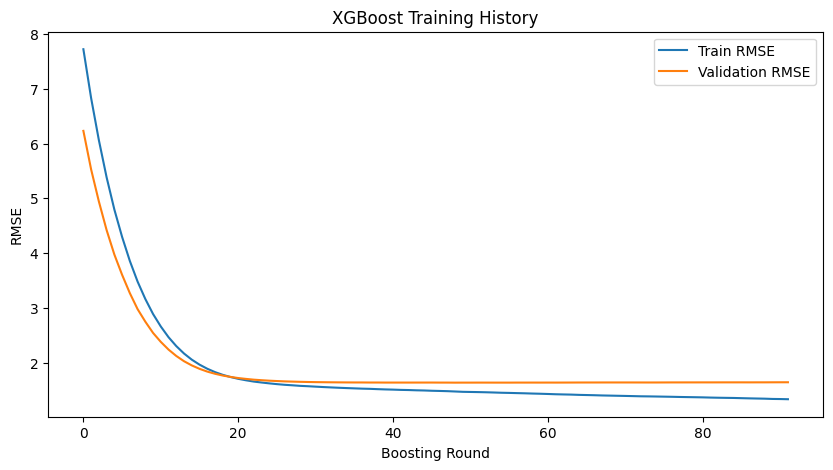

In [365]:
plt.figure(figsize=(10, 5))

plt.plot(
    train_rmse_history,
    label="Train RMSE"
)

plt.plot(
    val_rmse_history,
    label="Validation RMSE"
)

plt.xlabel("Boosting Round")
plt.ylabel("RMSE")
plt.title("XGBoost Training History")
plt.legend()

plt.show()

## 85. Prediction

In [366]:
xgb_train_pred = xgb_model.predict(
    X_train
)

xgb_val_pred = xgb_model.predict(
    X_val
)

xgb_test_pred = xgb_model.predict(
    X_test
)
print(
    "Negative train predictions:",
    (xgb_train_pred < 0).sum()
)

print(
    "Negative validation predictions:",
    (xgb_val_pred < 0).sum()
)

print(
    "Negative test predictions:",
    (xgb_test_pred < 0).sum()
)

Negative train predictions: 314991
Negative validation predictions: 135210
Negative test predictions: 182654


## 86. Hàm đánh giá

In [367]:
def regression_metrics(
    name,
    y_true,
    y_pred
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    # Range-normalized RMSE
    y_range = (
        y_true.max()
        - y_true.min()
    )

    nrmse = (
        rmse / y_range
        if y_range > 0
        else np.nan
    )

    # MAPE chỉ tính y != 0
    nonzero = np.abs(y_true) > 1e-6

    mape = (
        np.mean(
            np.abs(
                (
                    y_true[nonzero]
                    - y_pred[nonzero]
                )
                /
                y_true[nonzero]
            )
        )
        * 100
    )

    return pd.DataFrame({
        "Model": [name],
        "RMSE": [rmse],
        "NRMSE": [nrmse],
        "MAE": [mae],
        "MAPE (%)": [mape],
        "R2": [r2]
    })

## 87. Đánh giá Train / Validation / Test

In [368]:
xgb_train_metrics = regression_metrics(
    "XGBoost Train",
    y_train,
    xgb_train_pred
)

xgb_val_metrics = regression_metrics(
    "XGBoost Validation",
    y_val,
    xgb_val_pred
)

xgb_test_metrics = regression_metrics(
    "XGBoost Test",
    y_test,
    xgb_test_pred
)

# ghép
xgb_results = pd.concat(
    [
        xgb_train_metrics,
        xgb_val_metrics,
        xgb_test_metrics
    ],
    ignore_index=True
)

xgb_results

,Model,RMSE,NRMSE,MAE,MAPE (%),R2
0,XGBoost Train,1.332632,0.013431,0.430247,25.813515,0.976701
1,XGBoost Validation,1.642166,0.016588,0.438109,38.933666,0.943225
2,XGBoost Test,1.875180,0.020218,0.564830,28.136904,0.964308


## 88. Feature Importance

In [369]:
feature_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance":
        xgb_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance

,Feature,Importance
0,PV_mean_1h,0.436059
1,PV_mean_4h,0.240108
2,GHI_15min,0.095212
3,PV_std_1d,0.082076
4,PV_std_4h,0.043841
5,PV_std_1w,0.042276
6,Hour_sin,0.013509
7,GHI_clear,0.006937
8,PV_std_2d,0.006198
9,Hour_cos,0.006179


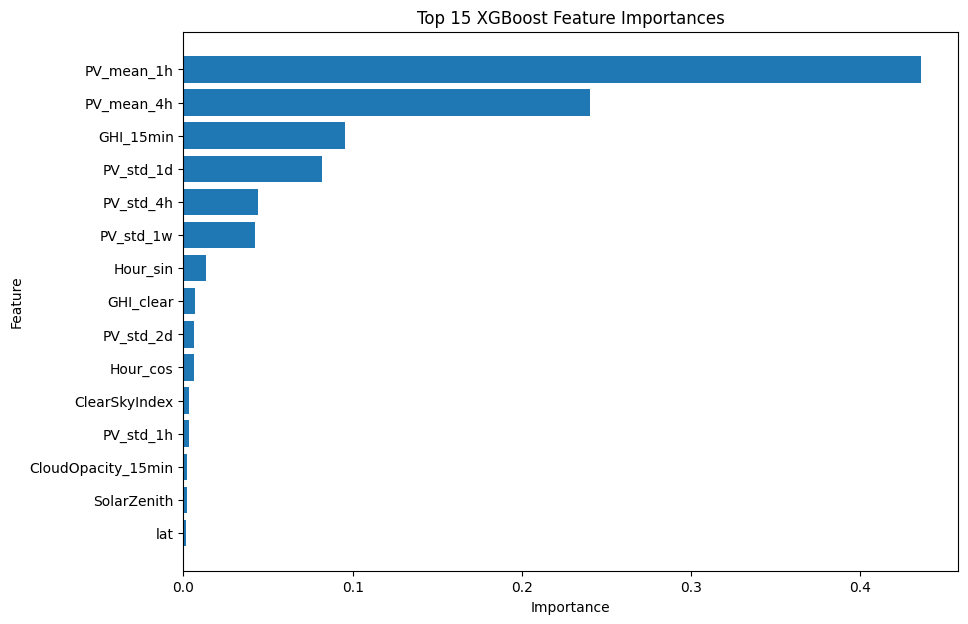

In [370]:
# vẽ top 15 
top15 = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top15["Feature"][::-1],
    top15["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "Top 15 XGBoost Feature Importances"
)

plt.show()

## 89. Actual vs Prediction trên Test

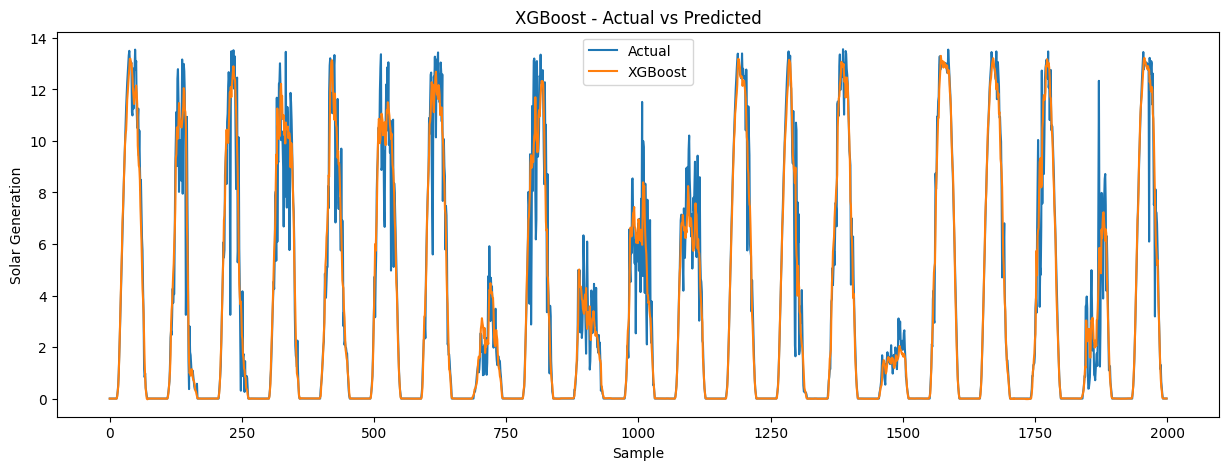

In [371]:
n_plot = min(
    2000,
    len(y_test)
)

plt.figure(figsize=(15, 5))

plt.plot(
    np.asarray(y_test)[:n_plot],
    label="Actual"
)

plt.plot(
    xgb_test_pred[:n_plot],
    label="XGBoost"
)

plt.xlabel("Sample")
plt.ylabel("Solar Generation")
plt.title(
    "XGBoost - Actual vs Predicted"
)

plt.legend()

plt.show()

## 90. Tạo residual cho LSTM

In [372]:
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["XGB_Pred"] = (
    xgb_train_pred.astype("float32")
)

val_df["XGB_Pred"] = (
    xgb_val_pred.astype("float32")
)

test_df["XGB_Pred"] = (
    xgb_test_pred.astype("float32")
)

# residual
train_df["Residual"] = (
    train_df["SolarGeneration"]
    -
    train_df["XGB_Pred"]
).astype("float32")

val_df["Residual"] = (
    val_df["SolarGeneration"]
    -
    val_df["XGB_Pred"]
).astype("float32")

test_df["Residual"] = (
    test_df["SolarGeneration"]
    -
    test_df["XGB_Pred"]
).astype("float32")

print(
    train_df["Residual"].describe()
)

count    1.190866e+06
mean    -1.318982e-04
std      1.331887e+00
min     -5.064104e+01
25%     -2.885644e-02
50%      3.291419e-04
75%      1.268747e-02
max      4.698528e+01
Name: Residual, dtype: float64


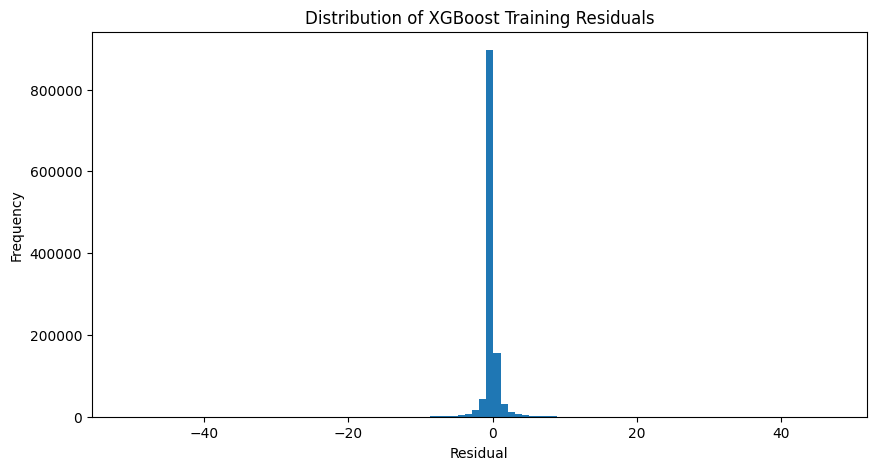

In [373]:
#Kiểm tra residual có centered quanh 0 không
plt.figure(figsize=(10, 5))

plt.hist(
    train_df["Residual"],
    bins=100
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title(
    "Distribution of XGBoost Training Residuals"
)

plt.show()

## 91. Import TensorFlow

In [374]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam

np.random.seed(42)
tf.random.set_seed(42)

## 92.Sắp xếp residual theo từng site

In [375]:
train_df = (
    train_df
    .sort_values(["SiteID", "Timestamp_UTC"])
    .reset_index(drop=True)
)

val_df = (
    val_df
    .sort_values(["SiteID", "Timestamp_UTC"])
    .reset_index(drop=True)
)

test_df = (
    test_df
    .sort_values(["SiteID", "Timestamp_UTC"])
    .reset_index(drop=True)
)

## 93. Tạo sequence residual 24 bước

In [376]:
LOOKBACK = 24

def create_residual_sequences(df, lookback=24):

    X_seq = []
    y_seq = []

    xgb_current = []
    y_current = []

    site_current = []
    time_current = []

    for site_id, group in df.groupby("SiteID"):

        group = (
            group
            .sort_values("Timestamp_UTC")
            .reset_index(drop=True)
        )

        residuals = (
            group["Residual"]
            .to_numpy(dtype=np.float32)
        )

        xgb_pred = (
            group["XGB_Pred"]
            .to_numpy(dtype=np.float32)
        )

        actual = (
            group["SolarGeneration"]
            .to_numpy(dtype=np.float32)
        )

        timestamps = (
            group["Timestamp_UTC"]
            .to_numpy()
        )

        for i in range(
            lookback,
            len(group)
        ):

            X_seq.append(
                residuals[
                    i-lookback:i
                ]
            )

            y_seq.append(
                residuals[i]
            )

            xgb_current.append(
                xgb_pred[i]
            )

            y_current.append(
                actual[i]
            )

            site_current.append(
                site_id
            )

            time_current.append(
                timestamps[i]
            )

    X_seq = np.array(
        X_seq,
        dtype=np.float32
    )

    y_seq = np.array(
        y_seq,
        dtype=np.float32
    )

    X_seq = X_seq.reshape(
        X_seq.shape[0],
        X_seq.shape[1],
        1
    )

    return (
        X_seq,
        y_seq,
        np.array(xgb_current),
        np.array(y_current),
        np.array(site_current),
        np.array(time_current)
    )

## 94. Tạo Train / Validation / Test sequences

In [377]:
(
    X_train_seq,
    y_train_res,
    xgb_train_aligned,
    y_train_aligned,
    site_train_seq,
    time_train_seq
) = create_residual_sequences(
    train_df,
    LOOKBACK
)

(
    X_val_seq,
    y_val_res,
    xgb_val_aligned,
    y_val_aligned,
    site_val_seq,
    time_val_seq
) = create_residual_sequences(
    val_df,
    LOOKBACK
)

(
    X_test_seq,
    y_test_res,
    xgb_test_aligned,
    y_test_aligned,
    site_test_seq,
    time_test_seq
) = create_residual_sequences(
    test_df,
    LOOKBACK
)

print("Train:", X_train_seq.shape)
print("Validation:", X_val_seq.shape)
print("Test:", X_test_seq.shape)

Train: (1189858, 24, 1)
Validation: (583338, 24, 1)
Test: (583338, 24, 1)


## 95. Heteroscedastic loss  

In [378]:
def heteroscedastic_loss(
    y_true,
    y_pred
):

    delta = y_pred[:, 0]

    log_var = y_pred[:, 1]

    # numerical stability
    log_var = tf.clip_by_value(
        log_var,
        -10.0,
        10.0
    )

    squared_error = tf.square(
        y_true - delta
    )

    loss = (
        0.5
        * tf.exp(-log_var)
        * squared_error
        +
        0.5
        * log_var
    )

    return tf.reduce_mean(loss)

## 96. Tạo Residual LSTM

In [379]:
residual_lstm = Sequential([
    
    LSTM(
        64,
        return_sequences=True,
        input_shape=(LOOKBACK, 1)
    ),

    LSTM(
        64
    ),

    Dense(2)
])

In [380]:
residual_lstm.compile(
    optimizer=Adam(
        learning_rate=0.001
    ),
    loss=heteroscedastic_loss
)

residual_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,050 (195.51 KB)

 Trainable params: 50,050 (195.51 KB)

 Non-trainable params: 0 (0.00 B)

## 97. Train 25 epochs

In [381]:
history = residual_lstm.fit(
    X_train_seq,
    y_train_res,

    validation_data=(
        X_val_seq,
        y_val_res
    ),

    epochs=25,
    batch_size=128,

    verbose=1
)

Epoch 1/25
9296/9296 ━━━━━━━━━━━━━━━━━━━━ 73s 8ms/step - loss: -0.8112 - val_loss: -1.0305
Epoch 2/25
9296/9296 ━━━━━━━━━━━━━━━━━━━━ 70s 8ms/step - loss: -1.1778 - val_loss: -1.7837
Epoch 3/25
9296/9296 ━━━━━━━━━━━━━━━━━━━━ 70s 8ms/step - loss: -1.2500 - val_loss: -1.1689
Epoch 4/25
9296/9296 ━━━━━━━━━━━━━━━━━━━━ 70s 8ms/step - loss: -1.3235 - val_loss: -1.2853
Epoch 5/25
9296/9296 ━━━━━━━━━━━━━━━━━━━━ 69s 7ms/step - loss: -1.2017 - val_loss: -1.5808
Epoch 6/25
9296/9296 ━━━━━━━━━━━━━━━━━━━━ 70s 7ms/step - loss: -1.4061 - val_loss: -1.1586
Epoch 7/25
9296/9296 ━━━━━━━━━━━━━━━━━━━━ 71s 8ms/step - loss: -1.4121 - val_loss: -1.8901
Epoch 8/25
9296/9296 ━━━━━━━━━━━━━━━━━━━━ 71s 8ms/step - loss: -1.1608 - val_loss: -2.0141
Epoch 9/25
9296/9296 ━━━━━━━━━━━━━━━━━━━━ 71s 8ms/step - loss: -1.4392 - val_loss: -1.6054
Epoch 10/25
9296/9296 ━━━━━━━━━━━━━━━━━━━━ 70s 8ms/step - loss: -1.4758 - val_loss: -1.6302
Epoch 11/25
9296/9296 ━━━━━━━━━━━━━━━━━━━━ 70s 8ms/step - loss: -1.5420 - val_loss: -1.55

## 98. Vẽ loss

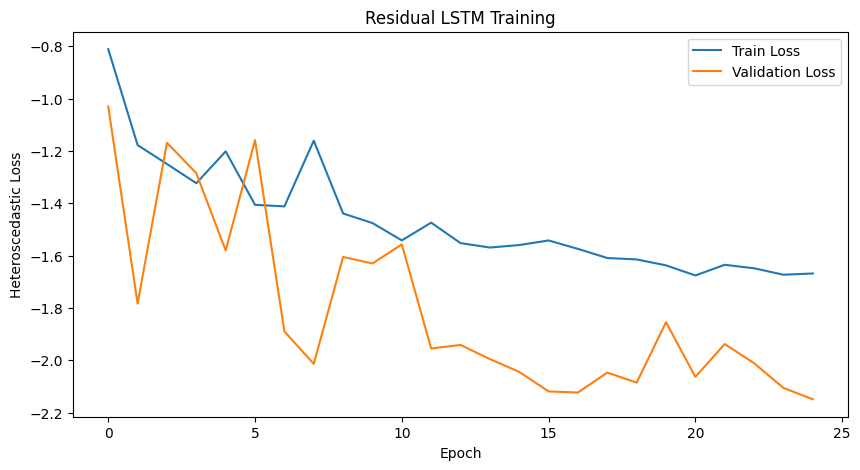

In [382]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Train Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Heteroscedastic Loss")
plt.title("Residual LSTM Training")
plt.legend()

plt.show()

## 99. Predict residual + uncertainty

In [383]:
test_out = residual_lstm.predict(
    X_test_seq,
    batch_size=128
)

delta_test = (
    test_out[:, 0]
)

log_var_test = (
    test_out[:, 1]
)

sigma_test = np.exp(
    0.5 * log_var_test
)

print(
    "Delta mean:",
    delta_test.mean()
)

print(
    "Sigma mean:",
    sigma_test.mean()
)

4558/4558 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step
Delta mean: -0.0151878055
Sigma mean: 0.7064861


## 100. Adaptive Hybrid

In [384]:
xgb_base = np.clip(
    xgb_test_aligned,
    0,
    None
)

weight_test = (
    1.0
    /
    (1.0 + sigma_test)
)

correction_limit = (
    0.5 * xgb_base
)

delta_clipped = np.clip(
    delta_test,
    -correction_limit,
    correction_limit
)

hybrid_test_pred = (
    xgb_base
    +
    weight_test
    * delta_clipped
)

hybrid_test_pred = np.clip(
    hybrid_test_pred,
    0,
    None
)

## 101. Đánh giá Hybrid

In [385]:
hybrid_test_metrics = regression_metrics(
    "Hybrid XGBoost-LSTM",
    y_test_aligned,
    hybrid_test_pred
)

hybrid_test_metrics  
xgb_aligned_metrics = regression_metrics(
    "XGBoost aligned",
    y_test_aligned,
    xgb_base
)

comparison = pd.concat(
    [
        xgb_aligned_metrics,
        hybrid_test_metrics
    ],
    ignore_index=True
)

comparison

,Model,RMSE,NRMSE,MAE,MAPE (%),R2
0,XGBoost aligned,1.876752,0.020235,0.563448,28.134520,0.964297
1,Hybrid XGBoost-LSTM,1.861155,0.020066,0.544841,25.481159,0.964888


## 101. Tạo Hybrid prediction cho Validation

In [386]:
val_out = residual_lstm.predict(
    X_val_seq,
    batch_size=128
)

delta_val = val_out[:, 0]
log_var_val = val_out[:, 1]

sigma_val = np.exp(
    0.5 * log_var_val
)

xgb_val_base = np.clip(
    xgb_val_aligned,
    0,
    None
)

weight_val = (
    1.0 /
    (1.0 + sigma_val)
)

correction_limit_val = (
    0.5 * xgb_val_base
)

delta_val_clipped = np.clip(
    delta_val,
    -correction_limit_val,
    correction_limit_val
)

hybrid_val_pred = (
    xgb_val_base
    +
    weight_val
    * delta_val_clipped
)

hybrid_val_pred = np.clip(
    hybrid_val_pred,
    0,
    None
)

print("Validation samples:", len(y_val_aligned))
print("Hybrid validation samples:", len(hybrid_val_pred))

4558/4558 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step
Validation samples: 583338
Hybrid validation samples: 583338


## 102. Hàm đánh giá Prediction Interval

In [387]:
def interval_metrics(
    y_true,
    lower,
    upper
):
    y_true = np.asarray(y_true)

    picp = np.mean(
        (y_true >= lower)
        &
        (y_true <= upper)
    )

    mpiw = np.mean(
        upper - lower
    )

    return picp, mpiw

## 103. Gaussian interval

In [388]:
gaussian_lower = (
    hybrid_test_pred
    -
    1.96 * sigma_test
)

gaussian_upper = (
    hybrid_test_pred
    +
    1.96 * sigma_test
)

gaussian_picp, gaussian_mpiw = (
    interval_metrics(
        y_test_aligned,
        gaussian_lower,
        gaussian_upper
    )
)

print("Gaussian PICP:", gaussian_picp)
print("Gaussian MPIW:", gaussian_mpiw)

Gaussian PICP: 0.9624934429095996
Gaussian MPIW: 2.7694247


## 104. Tìm T tối ưu trên Validation

In [389]:
from scipy.optimize import minimize_scalar
val_error = (
    y_val_aligned
    -
    hybrid_val_pred
)

sigma_val_safe = np.maximum(
    sigma_val,
    1e-6
)
def temperature_nll(T):

    scaled_sigma = (
        T * sigma_val_safe
    )

    return np.mean(
        np.log(scaled_sigma)
        +
        0.5
        * (
            val_error
            / scaled_sigma
        ) ** 2
    )
# tối ưu
temperature_result = minimize_scalar(
    temperature_nll,
    bounds=(0.05, 10.0),
    method="bounded"
)

T_star = temperature_result.x

print(
    "Optimal Temperature T:",
    T_star
)

Optimal Temperature T: 0.9900427757635474


## 105. Monte Carlo M=20

In [390]:
M = 20

rng = np.random.default_rng(42)

epsilon = rng.standard_normal(
    size=(
        M,
        len(hybrid_test_pred)
    )
).astype("float32")

mc_samples = (
    hybrid_test_pred[
        None, :
    ]
    +
    T_star
    * sigma_test[
        None, :
    ]
    * epsilon
).astype("float32")

print(
    "MC samples shape:",
    mc_samples.shape
)

MC samples shape: (20, 583338)


## 106. MC 95% interval

In [391]:
mc_lower = np.quantile(
    mc_samples,
    0.025,
    axis=0
)

mc_upper = np.quantile(
    mc_samples,
    0.975,
    axis=0
)
mc_picp, mc_mpiw = (
    interval_metrics(
        y_test_aligned,
        mc_lower,
        mc_upper
    )
)

print("MC PICP:", mc_picp)
print("MC MPIW:", mc_mpiw)

MC PICP: 0.9322725418196655
MC MPIW: 2.3050137


## 107. Calibration residual

In [392]:
conformal_errors = np.abs(
    y_val_aligned
    -
    hybrid_val_pred
)

alpha = 0.05

q_conformal = np.quantile(
    conformal_errors,
    1 - alpha / 2
)

print(
    "Conformal quantile:",
    q_conformal
)

Conformal quantile: 3.5451164


## 108. Conformal interval

In [393]:
conformal_lower = (
    hybrid_test_pred
    -
    q_conformal
)

conformal_upper = (
    hybrid_test_pred
    +
    q_conformal
)
conformal_picp, conformal_mpiw = (
    interval_metrics(
        y_test_aligned,
        conformal_lower,
        conformal_upper
    )
)

print(
    "Conformal PICP:",
    conformal_picp
)

print(
    "Conformal MPIW:",
    conformal_mpiw
)

Conformal PICP: 0.9674819744299189
Conformal MPIW: 7.0902386


## 109. CRPS cho Gaussian

In [394]:
from scipy.stats import norm
def gaussian_crps(
    y,
    mu,
    sigma
):
    sigma = np.maximum(
        sigma,
        1e-6
    )

    z = (
        (y - mu)
        / sigma
    )
    

    crps = sigma * (
        z * (
            2 * norm.cdf(z) - 1
        )
        +
        2 * norm.pdf(z)
        -
        1 / np.sqrt(np.pi)
    )

    return np.mean(crps)

gaussian_crps_value = gaussian_crps(
    np.asarray(y_test_aligned),
    hybrid_test_pred,
    sigma_test
)

print(
    "Gaussian CRPS:",
    gaussian_crps_value
)

Gaussian CRPS: 0.40549295282371783


## 110. CRPS cho MC Ensemble

In [395]:
def ensemble_crps(
    y_true,
    samples
):
    y_true = np.asarray(
        y_true,
        dtype=np.float32
    )

    M = samples.shape[0]

    term1 = np.mean(
        np.abs(
            samples
            -
            y_true[None, :]
        ),
        axis=0
    )

    sorted_samples = np.sort(
        samples,
        axis=0
    )

    j = np.arange(
        1,
        M + 1,
        dtype=np.float32
    )

    coeff = (
        2 * j
        - M
        - 1
    )[:, None]

    term2 = (
        np.sum(
            coeff
            * sorted_samples,
            axis=0
        )
        /
        (M ** 2)
    )

    return np.mean(
        term1 - term2
    )

mc_crps_value = ensemble_crps(
    y_test_aligned,
    mc_samples
)

print(
    "MC CRPS:",
    mc_crps_value
)

MC CRPS: 0.42586845


## 111. Pinball Loss

In [396]:
def pinball_loss(
    y_true,
    y_pred_quantile,
    tau
):
    error = (
        y_true
        -
        y_pred_quantile
    )

    return np.mean(
        np.maximum(
            tau * error,
            (tau - 1) * error
        )
    )

# GAUSSIAN
gaussian_pinball = (
    pinball_loss(
        np.asarray(y_test_aligned),
        gaussian_lower,
        0.025
    )
    +
    pinball_loss(
        np.asarray(y_test_aligned),
        gaussian_upper,
        0.975
    )
) / 2

# MC
mc_pinball = (
    pinball_loss(
        np.asarray(y_test_aligned),
        mc_lower,
        0.025
    )
    +
    pinball_loss(
        np.asarray(y_test_aligned),
        mc_upper,
        0.975
    )
) / 2

## 112. Bảng kết quả Uncertainty

In [397]:
uncertainty_results = pd.DataFrame({
    "Method": [
        "Gaussian (Uncalibrated)",
        "MC Ensemble (Calibrated)",
        "Conformal Prediction"
    ],

    "PICP": [
        gaussian_picp,
        mc_picp,
        conformal_picp
    ],

    "MPIW": [
        gaussian_mpiw,
        mc_mpiw,
        conformal_mpiw
    ],

    "CRPS": [
        gaussian_crps_value,
        mc_crps_value,
        np.nan
    ],

    "Pinball Loss": [
        gaussian_pinball,
        mc_pinball,
        np.nan
    ]
})

uncertainty_results

,Method,PICP,MPIW,CRPS,Pinball Loss
0,Gaussian (Uncalibrated),0.962493,2.769425,0.405493,0.055851
1,MC Ensemble (Calibrated),0.932273,2.305014,0.425868,0.065142
2,Conformal Prediction,0.967482,7.090239,NaN,NaN


## 113. Vẽ Prediction Interval

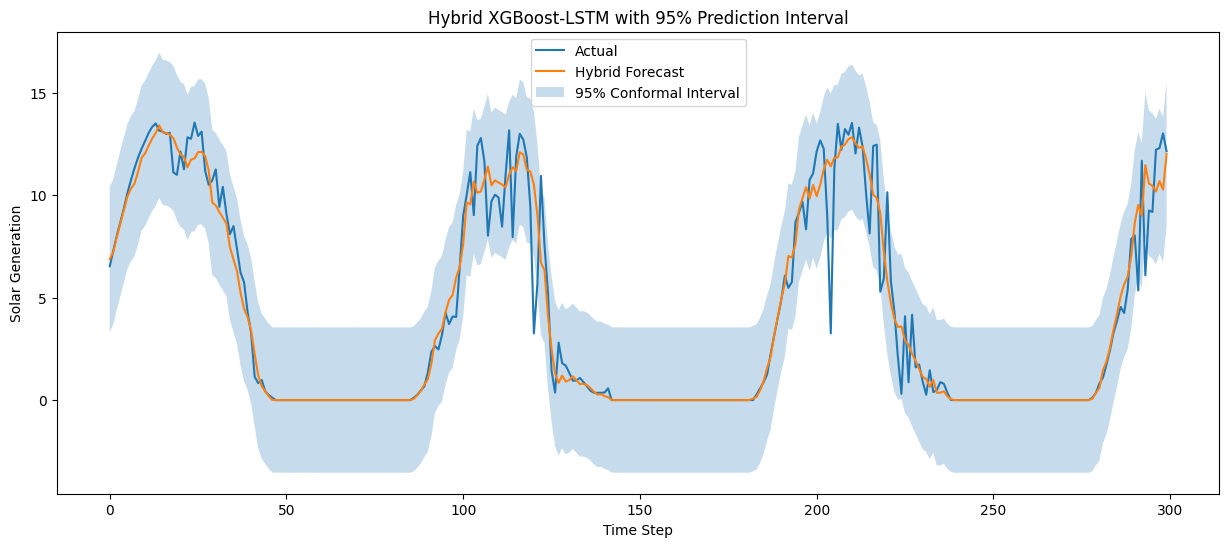

In [398]:
n_plot = 300

x_plot = np.arange(
    n_plot
)

plt.figure(
    figsize=(15, 6)
)

plt.plot(
    x_plot,
    y_test_aligned[:n_plot],
    label="Actual"
)

plt.plot(
    x_plot,
    hybrid_test_pred[:n_plot],
    label="Hybrid Forecast"
)

plt.fill_between(
    x_plot,
    conformal_lower[:n_plot],
    conformal_upper[:n_plot],
    alpha=0.25,
    label="95% Conformal Interval"
)

plt.xlabel("Time Step")
plt.ylabel("Solar Generation")

plt.title(
    "Hybrid XGBoost-LSTM with 95% Prediction Interval"
)

plt.legend()

plt.show()

## 114. Tạo bảng test đã align với Hybrid

In [399]:
hybrid_eval = pd.DataFrame({
    "SiteID": site_test_seq.astype(str),
    "Timestamp_UTC": pd.to_datetime(
        time_test_seq,
        utc=True
    ),
    "Actual": y_test_aligned,
    "XGBoost": xgb_base,
    "Hybrid": hybrid_test_pred
})

hybrid_eval.head()

,SiteID,Timestamp_UTC,Actual,XGBoost,Hybrid
0,1_14,2021-11-29 21:45:00+00:00,6.531250,6.833686,6.875969
1,1_14,2021-11-29 22:00:00+00:00,7.281250,7.306411,7.225710
2,1_14,2021-11-29 22:15:00+00:00,8.023438,7.923642,7.950535
3,1_14,2021-11-29 22:30:00+00:00,8.679688,8.556146,8.615733
4,1_14,2021-11-29 22:45:00+00:00,9.359375,9.247060,9.269831


## 115. Tạo các baseline

In [400]:
baseline_test = (
    test_df[
        [
            "SiteID",
            "Timestamp_UTC",
            "SolarGeneration",
            "GHI_15min",
            "Hour"
        ]
    ]
    .copy()
    .sort_values(
        ["SiteID", "Timestamp_UTC"]
    )
)

In [401]:
# persistence 1h
baseline_test["Persistence_1h"] = (
    baseline_test
    .groupby("SiteID")["SolarGeneration"]
    .shift(4)
)
# persistence 2h
baseline_test["Persistence_24h"] = (
    baseline_test
    .groupby("SiteID")["SolarGeneration"]
    .shift(96)
)
# zezo model
baseline_test["Zero"] = 0.0

## 116. Smart Persistence

In [402]:
baseline_test["GHI_lag_1h"] = (
    baseline_test
    .groupby("SiteID")["GHI_15min"]
    .shift(4)
)

ghi_now = baseline_test["GHI_15min"]
ghi_prev = baseline_test["GHI_lag_1h"]
pv_prev = baseline_test["Persistence_1h"]

baseline_test["Smart_Persistence"] = np.where(
    # Nếu hiện tại gần như không có nắng
    ghi_now <= 5,
    0.0,

    np.where(
        # Nếu cả hiện tại và 1 giờ trước đều có irradiance
        ghi_prev > 5,

        pv_prev * (
            ghi_now / ghi_prev
        ),

        # Không đủ GHI quá khứ → fallback persistence
        pv_prev
    )
)

baseline_test["Smart_Persistence"] = (
    baseline_test["Smart_Persistence"]
    .clip(lower=0)
)

## 117. Climatology chỉ học từ TRAIN

In [403]:
climatology = (
    train_df
    .groupby(
        ["SiteID", "Hour"]
    )["SolarGeneration"]
    .mean()
    .rename("Climatology")
    .reset_index()
)

baseline_test = baseline_test.merge(
    climatology,
    on=["SiteID", "Hour"],
    how="left",
    validate="many_to_one"
)

## 118. Ghép baseline với Hybrid

In [404]:
baseline_compare = hybrid_eval.merge(
    baseline_test[
        [
            "SiteID",
            "Timestamp_UTC",
            "Persistence_1h",
            "Persistence_24h",
            "Smart_Persistence",
            "Zero",
            "Climatology"
        ]
    ],
    on=[
        "SiteID",
        "Timestamp_UTC"
    ],
    how="left"
)
baseline_compare.head()

,SiteID,Timestamp_UTC,Actual,XGBoost,Hybrid,Persistence_1h,Persistence_24h,Smart_Persistence,Zero,Climatology
0,1_14,2021-11-29 21:45:00+00:00,6.531250,6.833686,6.875969,3.179688,NaN,4.529649,0.0,2.310417
1,1_14,2021-11-29 22:00:00+00:00,7.281250,7.306411,7.225710,4.031250,NaN,5.733521,0.0,4.431820
2,1_14,2021-11-29 22:15:00+00:00,8.023438,7.923642,7.950535,4.882812,NaN,6.629342,0.0,4.431820
3,1_14,2021-11-29 22:30:00+00:00,8.679688,8.556146,8.615733,5.726562,NaN,7.506066,0.0,4.431820
4,1_14,2021-11-29 22:45:00+00:00,9.359375,9.247060,9.269831,6.531250,NaN,8.335783,0.0,4.431820


## 119. Dùng cùng sample cho tất cả model

In [405]:
compare_cols = [
    "Actual",
    "XGBoost",
    "Hybrid",
    "Persistence_1h",
    "Persistence_24h",
    "Smart_Persistence",
    "Zero",
    "Climatology"
]

baseline_compare_clean = (
    baseline_compare
    .dropna(
        subset=compare_cols
    )
    .reset_index(drop=True)
)

print(
    "Samples used:",
    len(baseline_compare_clean)
)

Samples used: 580314


## 120. Đánh giá toàn bộ baseline

In [406]:
baseline_results = []

models_to_evaluate = {
    "Zero Model": "Zero",
    "Persistence (1h)": "Persistence_1h",
    "Smart Persistence": "Smart_Persistence",
    "Persistence (24h)": "Persistence_24h",
    "Climatology": "Climatology",
    "XGBoost": "XGBoost",
    "Hybrid XGBoost-LSTM": "Hybrid"
}

for model_name, column in models_to_evaluate.items():

    result = regression_metrics(
        model_name,
        baseline_compare_clean["Actual"],
        baseline_compare_clean[column]
    )

    baseline_results.append(
        result
    )

baseline_results = pd.concat(
    baseline_results,
    ignore_index=True
)

baseline_results

baseline_results.sort_values(
    "RMSE"
)

,Model,RMSE,NRMSE,MAE,MAPE (%),R2
6,Hybrid XGBoost-LSTM,1.858589,0.020039,0.544177,25.544781,0.964798
5,XGBoost,1.874204,0.020207,0.562772,28.204800,0.964204
2,Smart Persistence,3.107068,0.033499,1.002095,45.770351,0.901622
1,Persistence (1h),3.845507,0.041461,1.500134,97.472473,0.849304
4,Climatology,4.476937,0.048269,1.796198,107.796753,0.795753
3,Persistence (24h),4.780752,0.051544,1.499950,80.573555,0.767090
0,Zero Model,10.766347,0.116079,4.217045,100.000000,-0.181222


## 121. Tính mức cải thiện Hybrid so với XGBoost

In [407]:
xgb_rmse = (
    baseline_results.loc[
        baseline_results["Model"] == "XGBoost",
        "RMSE"
    ].iloc[0]
)

hybrid_rmse = (
    baseline_results.loc[
        baseline_results["Model"]
        == "Hybrid XGBoost-LSTM",
        "RMSE"
    ].iloc[0]
)

improvement = (
    (xgb_rmse - hybrid_rmse)
    /
    xgb_rmse
    * 100
)

print(
    f"Hybrid RMSE improvement over XGBoost: "
    f"{improvement:.2f}%"
)

Hybrid RMSE improvement over XGBoost: 0.83%


## 122. Định nghĩa các nhóm feature

In [408]:
weather_features = [
    "AirTemperature",
    "ApparentTemperature",
    "DewPointTemperature",
    "RelativeHumidity",
    "WindSpeed",
    "WindDir_sin",
    "WindDir_cos",
    "VaporPressure",
    "TempDiff"
]

time_features = [
    "Hour_sin",
    "Hour_cos",
    "Day_sin",
    "Day_cos"
]

solar_features = [
    "GHI_15min",
    "GHI_clear",
    "ClearSkyIndex",
    "CloudOpacity_15min",
    "SolarZenith"
]

lag_features = history_cols

## 123. Tạo các trường hợp ablation

In [409]:
ablation_groups = {
    "All Features": [],
    "No Weather": weather_features,
    "No Time": time_features,
    "No Solar": solar_features,
    "No Lag": lag_features
}

## 124. Huấn luyện lại XGBoost khi bỏ từng nhóm

In [410]:
ablation_results = []

for name, removed_cols in ablation_groups.items():

    selected_features = [
        col for col in feature_cols
        if col not in removed_cols
    ]

    model = XGBRegressor(
        **xgb_model.get_params()
    )

    model.fit(
        train_df[selected_features],
        train_df["SolarGeneration"],
        verbose=False
    )

    predictions = np.clip(
        model.predict(
            test_df[selected_features]
        ),
        0,
        None
    )

    metrics = regression_metrics(
        name,
        test_df["SolarGeneration"],
        predictions
    )

    ablation_results.append(metrics)

ablation_results = pd.concat(
    ablation_results,
    ignore_index=True
)

display(ablation_results)

,Model,RMSE,NRMSE,MAE,MAPE (%),R2
0,All Features,1.875161,0.020217,0.562631,28.119448,0.964309
1,No Weather,1.866941,0.020129,0.556159,28.120705,0.964621
2,No Time,1.874864,0.020214,0.569653,28.890085,0.964320
3,No Solar,2.098304,0.022623,0.641139,32.901428,0.955309
4,No Lag,10.477727,0.112967,4.475362,289.599701,-0.114339


## 125. Tính mức suy giảm khi bỏ feature

In [411]:
baseline_rmse = ablation_results.loc[
    ablation_results["Model"] == "All Features",
    "RMSE"
].iloc[0]

ablation_results["Delta_RMSE_%"] = (
    (
        ablation_results["RMSE"]
        - baseline_rmse
    )
    / baseline_rmse
    * 100
)

display(
    ablation_results.sort_values("RMSE")
)

,Model,RMSE,NRMSE,MAE,MAPE (%),R2,Delta_RMSE_%
1,No Weather,1.866941,0.020129,0.556159,28.120705,0.964621,-0.438348
2,No Time,1.874864,0.020214,0.569653,28.890085,0.964320,-0.015841
0,All Features,1.875161,0.020217,0.562631,28.119448,0.964309,0.000000
3,No Solar,2.098304,0.022623,0.641139,32.901428,0.955309,11.899942
4,No Lag,10.477727,0.112967,4.475362,289.599701,-0.114339,458.764148


## 126. Thêm 2 thí nghiệm

In [412]:
extra_groups = {
    "No Cyclical": [
        "Hour_sin", "Hour_cos",
        "Day_sin", "Day_cos"
    ],
    "Only Lag": [
        col for col in feature_cols
        if col not in lag_features
    ]
}

extra_results = []

for name, removed_cols in extra_groups.items():

    selected_features = [
        col for col in feature_cols
        if col not in removed_cols
    ]

    model = XGBRegressor(**xgb_model.get_params())

    model.fit(
        train_df[selected_features],
        train_df["SolarGeneration"],
        verbose=False
    )

    predictions = np.clip(
        model.predict(test_df[selected_features]),
        0,
        None
    )

    result = regression_metrics(
        name,
        test_df["SolarGeneration"],
        predictions
    )

    extra_results.append(result)

extra_results = pd.concat(
    extra_results,
    ignore_index=True
)

ablation_results = pd.concat(
    [
        ablation_results.drop(columns="Delta_RMSE_%"),
        extra_results
    ],
    ignore_index=True
)

## 127. Tính lại bảng cuối

In [413]:
baseline_rmse = ablation_results.loc[
    ablation_results["Model"] == "All Features",
    "RMSE"
].iloc[0]

ablation_results["Delta_RMSE_%"] = (
    (ablation_results["RMSE"] - baseline_rmse)
    / baseline_rmse * 100
)

display(ablation_results.sort_values("RMSE"))

,Model,RMSE,NRMSE,MAE,MAPE (%),R2,Delta_RMSE_%
1,No Weather,1.866941,0.020129,0.556159,28.120705,0.964621,-0.438348
2,No Time,1.874864,0.020214,0.569653,28.890085,0.964320,-0.015841
5,No Cyclical,1.874864,0.020214,0.569653,28.890085,0.964320,-0.015841
0,All Features,1.875161,0.020217,0.562631,28.119448,0.964309,0.000000
3,No Solar,2.098304,0.022623,0.641139,32.901428,0.955309,11.899942
6,Only Lag,2.189645,0.023608,0.677259,34.950264,0.951333,16.771055
4,No Lag,10.477727,0.112967,4.475362,289.599701,-0.114339,458.764148


In [419]:
baseline_results.to_csv(
    "/kaggle/working/baseline_results_old.csv",
    index=False
)

ablation_results.to_csv(
    "/kaggle/working/ablation_results_old.csv",
    index=False
)

uncertainty_results.to_csv(
    "/kaggle/working/uncertainty_results_old.csv",
    index=False
)